# Phase 4: Robustness, Validation and Model Diagnostics

## Objective
Phase 3 tested the FF-5 model with one set of construction choices (2×3 sorts, June formation, median size breakpoint, value weights, financials excluded from RMW only) on one sample (Jul-2016 onwards). This phase checks whether the Phase 3 conclusions still hold when those choices change, when the sample is split, when the factors are compared with independent sources, and when the model faces portfolios it was not built on, as Fama & French (2015) do before trusting any result.

## Questions this phase answers
1. Are the factors built correctly? (IIMA factor library, NSE total-return indices)
2. Do the factor premia and model tests survive other reasonable construction choices?
3. Is HML still redundant once the construction changes?
4. Are the results stable over time, and do they depend on the Covid months?
5. Does the model price portfolios it was **not** built on (industries)?
6. Do the GRS conclusions survive non-normal residuals (bootstrap)?
7. How much does momentum, which FF-5 leaves out, change the picture (Carhart, FF-6)?
8. Does the Phase 3 multi-factor portfolio hold up under other costs, weights, caps, selection sizes and sample periods?

## Inputs
- **Phase 1:** `run_manifest.json`, `monthly_panel.csv` (full return history, for momentum), NSE TRI files in `raw/external/nse_tri/` (Phase 1 Step 10.4)
- **Phase 2:** `phase_2_ff5_factors.csv`, `phase_2_monthly_panel_clean.csv`, `phase_2_formation.csv`, `phase_2_manifest.json`
- **Phase 3 (baseline):** factor summary, spanning regressions, test portfolios, model comparison, portfolio scores, returns and benchmarks, `phase_3_manifest.json`
- **External:** IIMA Indian Fama-French-Momentum factors (survivorship-bias adjusted) in `raw/external/`

## Steps
0. **Setup:** load inputs and check they are the ones Phase 3 used.
1. **Freeze the baseline:** Phase 3 results rebuilt and matched; compared with the superseded v1 run.
2. **External validation:** IIMA factors and NSE index checks.
3. **Alternative factor constructions**, with spanning tests.
4. **Time stability:** two halves, and without the Covid months.
5. **Industry portfolios** as out-of-sample test assets.
6. **Statistical robustness:** residual normality and bootstrap GRS.
7. **Momentum:** UMD, Carhart and FF-6.
8. **Portfolio robustness:** the Phase 3 multi-factor portfolio with one rule changed at a time, and by sample period.
9. **Verdict:** each Phase 3 conclusion marked Pass / Fragile / Fail.

## Rules (classical FF-5)
- **FF-5 stays the main model.** Momentum is not part of FF-5; Carhart and FF-6 are comparisons only.
- **Value-weighted factors and portfolios** are the baseline; equal weighting is a diagnostic only.
- **Change one choice at a time**, so every difference can be traced to its cause.
- **Pass / Fragile / Fail rules are fixed in Step 1**, before any Phase 4 result is seen.

## Outputs
- **Tables:** `phase_4_*.csv` plus one combined `phase_4_results.xlsx`
- **Plots:** `plots/phase_4/`

## Limitations
- About 10 years of monthly data; each half has about 60 months, so tests within a half have low power.
- Many regressions are run here, so a few significant results are expected by chance. No single result is called a finding.
- Industry labels are each stock's current broad sector (Screener, NSE classification, delisted stocks included), not point-in-time labels.

## Next
**Phase 5** uses only what passes here: attribution of stocks and funds, alpha screening and the final report.

### Revision note: why Phase 4 was paused and restarted

The first Phase 4 run (Oct-2026) stopped after Step 2, because external validation showed that the Phase 1 v1 data were wrong:
- **Survivorship bias:** the universe was today's Nifty 500 list followed back to 2016. Our SMB earned 15.6% a year against 4–5.5% for survivorship-free NSE index spreads, and 1.44% a month more than IIMA's SMB (t = 5.6).
- **Uncorrected corporate actions and wrong market caps:** fake crashes on split/bonus dates (e.g. RELIANCE Sep-2017, BAJFINANCE Jun-2025) and June-2016 market caps up to 10× too high; our market return trailed the Nifty 500 TRI by about 4% a year.

Phase 1 was rebuilt (point-in-time universe, full corporate-action handling; details in the **Phase 1 revision log**) and Phases 2–3 were rerun. All v1 results are superseded. Steps 1 and 2 show the key v1 numbers next to this run's; nothing else from v1 is kept.

In [1]:
# ==========================================================
# STEP 0: Imports, Settings and Paths
# ==========================================================

import json
import pandas as pd
import numpy as np
from pathlib import Path

import statsmodels.api as sm        # OLS regressions with Newey-West errors
from scipy import stats             # F, chi-square and normality tests
import matplotlib.pyplot as plt     # all plots
import seaborn as sns               # bar charts
from IPython.display import display

PROJECT_ROOT = Path().resolve().parent
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
EXTERNAL_DIR = DATA_DIR / "raw" / "external"
TRI_DIR = EXTERNAL_DIR / "nse_tri"                  # downloaded in Phase 1 Step 10.4

OUTPUT_DIR = PROCESSED_DIR                          # Phase 4 CSVs and xlsx saved here
PLOTS_DIR = PROJECT_ROOT / "plots" / "phase_4"      # Phase 4 PNG plots saved here
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    # Phase 1
    "phase1_manifest":  PROCESSED_DIR / "run_manifest.json",
    "phase1_panel":     PROCESSED_DIR / "monthly_panel.csv",          # full return history (Step 7)
    # Phase 2
    "factors":          PROCESSED_DIR / "phase_2_ff5_factors.csv",
    "panel":            PROCESSED_DIR / "phase_2_monthly_panel_clean.csv",
    "formation":        PROCESSED_DIR / "phase_2_formation.csv",
    "phase2_manifest":  PROCESSED_DIR / "phase_2_manifest.json",
    # Phase 3 (baseline)
    "phase3_manifest":  PROCESSED_DIR / "phase_3_manifest.json",
    "test_portfolios":  PROCESSED_DIR / "phase_3_test_portfolios.csv",
    "factor_summary":   PROCESSED_DIR / "phase_3_factor_summary.csv",
    "spanning":         PROCESSED_DIR / "phase_3_spanning_regressions.csv",
    "model_comparison": PROCESSED_DIR / "phase_3_model_comparison.csv",
    "portfolio_scores": PROCESSED_DIR / "phase_3_portfolio_scores.csv",   # Step 8
    "portfolio_returns": PROCESSED_DIR / "phase_3_portfolio_returns.csv", # Step 8
    "benchmarks":       PROCESSED_DIR / "phase_3_benchmarks.csv",         # Step 8
}

for name, f in FILES.items():
    print(f"{f.name:36s} ->", "found" if f.exists() else "MISSING")
assert all(f.exists() for f in FILES.values()), "An input file is missing: run Phases 1-3 first"

# Phase 3 must have been run AFTER Phase 2 (never mix runs)
p3_keys = ["phase3_manifest", "test_portfolios", "factor_summary", "spanning", "model_comparison",
           "portfolio_scores", "portfolio_returns", "benchmarks"]
old = [FILES[k].name for k in p3_keys if FILES[k].stat().st_mtime < FILES["factors"].stat().st_mtime]
assert not old, f"Re-run Phase 3 first, these are older than the Phase 2 factors: {old}"

# Remove earlier Phase 4 outputs, so this run's files and workbook never mix with an older run
for f in OUTPUT_DIR.glob("phase_4_*"):
    f.unlink()

run_manifest.json                    -> found
monthly_panel.csv                    -> found
phase_2_ff5_factors.csv              -> found
phase_2_monthly_panel_clean.csv      -> found
phase_2_formation.csv                -> found
phase_2_manifest.json                -> found
phase_3_manifest.json                -> found
phase_3_test_portfolios.csv          -> found
phase_3_factor_summary.csv           -> found
phase_3_spanning_regressions.csv     -> found
phase_3_model_comparison.csv         -> found
phase_3_portfolio_scores.csv         -> found
phase_3_portfolio_returns.csv        -> found
phase_3_benchmarks.csv               -> found


In [2]:
# 0.1 Settings: model rules are read from the Phase 2 and Phase 3 run records, never typed again

p1 = json.loads(FILES["phase1_manifest"].read_text())
p2 = json.loads(FILES["phase2_manifest"].read_text())
p3 = json.loads(FILES["phase3_manifest"].read_text())

BP_LOW, BP_HIGH = p2["bp_low"], p2["bp_high"]           # 30th / 70th percentile breakpoints
MIN_STOCKS = p2["min_stocks"]                           # min stocks per portfolio-month
FORMATIONS_USED = pd.to_datetime(p2["formations_used"]) # Junes whose factors are in the sample
NW_LAGS = p3["nw_lags"]                                 # Newey-West lags
MODELS = p3["models"]                                   # CAPM, FF3, FF4_noHML, FF5 (Carhart, FF6 in Step 7)
FLAGGED_PORTFOLIOS = p3["flagged_portfolios"]
FACTOR_COLS = ["MKT", "SMB", "HML", "RMW", "CMA"]
PORTFOLIO_SPEC = p3["portfolio_spec"]                   # Phase 3 portfolio rules (Step 8)
PORTFOLIOS = p3["portfolios"]
MAIN_PORTFOLIO = p3["main_portfolio"]

# Phase 4 settings, fixed before any Phase 4 result is seen
T_CRIT = 2.0                    # FF rule of thumb: |t| > 2 is significant (Newey-West t)
ALPHA = 0.05                    # significance level for GRS
SPLIT_DATE = "2021-06-30"       # first half Jul-2016 to Jun-2021 (60 months); second half after it
COVID_MONTHS = pd.to_datetime(["2020-03-31", "2020-04-30", "2020-05-31", "2020-06-30"])  # crash + rebound
TOP_N_BIG = 100                 # alternative size rule: Big = 100 largest stocks each June (Nifty 100 analog)
MIN_INDUSTRY_STOCKS = 10        # a sector needs this many stocks in every June, else it joins "Other"
N_BOOT = 2000                   # bootstrap repetitions (Step 6)
SEED = 42                       # fixed seed: the bootstrap gives the same result on every run

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

print("Phase 1 data cutoff:", p1["end_date"], "| Screener snapshot:", p1["screener_snapshot"])
print("Phase 2 factors:", p2["first_factor_month"], "->", p2["last_factor_month"], "|", p2["n_months"], "months")
print("Phase 3 models:", list(MODELS), "| flagged portfolios:", FLAGGED_PORTFOLIOS or "none")

Phase 1 data cutoff: 2026-10-31 | Screener snapshot: 2026-10-14
Phase 2 factors: 2016-07-31 -> 2026-09-30 | 123 months
Phase 3 models: ['CAPM', 'FF3', 'FF4_noHML', 'FF5'] | flagged portfolios: none


In [3]:
# 0.2 Load Phase 2 and Phase 3 files

df_factors = pd.read_csv(FILES["factors"], parse_dates=["date"], index_col="date").sort_index()
panel_df = pd.read_csv(FILES["panel"], parse_dates=["date", "formation_date"])
formation_df = pd.read_csv(FILES["formation"], parse_dates=["formation_date"])
formation_df["is_financial"] = formation_df["is_financial"].astype(bool)

factor_summary_p3 = pd.read_csv(FILES["factor_summary"], index_col=0)     # index = factor
spanning_p3 = pd.read_csv(FILES["spanning"], index_col=0)                 # index = factor
model_comparison_p3 = pd.read_csv(FILES["model_comparison"])
test_ports_df = pd.read_csv(FILES["test_portfolios"], parse_dates=["date"])

# Wide table of excess returns: one column per test portfolio (as in Phase 3)
excess_wide = test_ports_df.pivot(index="date", columns="portfolio_id", values="excess_ret").sort_index()
port_info = (test_ports_df[["portfolio_id", "sort_type", "size_group", "char_group"]]
             .drop_duplicates().set_index("portfolio_id"))

print("Factor months:", len(df_factors), "|", df_factors.index.min().date(), "->", df_factors.index.max().date())
print("Test portfolios:", excess_wide.shape[1], "| months:", len(excess_wide))
print("Panel stock-months:", len(panel_df), "| formation stock-years:", len(formation_df))

Factor months: 123 | 2016-07-31 -> 2026-09-30
Test portfolios: 27 | months: 123
Panel stock-months: 61677 | formation stock-years: 5488


In [4]:
# 0.3 Check that the inputs are the ones Phase 3 used (if a check fails, rerun Phases 2-3)

mean_gap = (df_factors[FACTOR_COLS].mean() * 100
            - factor_summary_p3.loc[FACTOR_COLS, "mean_monthly_%"]).abs().max()

checks = {
    "test portfolios cover the factor months": excess_wide.index.equals(df_factors.index),
    "no missing excess returns": excess_wide.isna().sum().sum() == 0,
    "factor months match Phase 3": len(df_factors) == p3["n_months"],
    "factor means match Phase 3": mean_gap < 1e-8,
    "all Phase 3 models in model comparison": set(model_comparison_p3["model"]) == set(MODELS),
    "sector label in panel and formation": "broad_sector" in panel_df and "broad_sector" in formation_df,
}
for name, passed in checks.items():
    print(f"{name:42s} -> {'PASS' if passed else 'FAIL'}")
assert all(checks.values()), "Inputs differ from Phase 3: rerun Phases 2-3"

test portfolios cover the factor months    -> PASS
no missing excess returns                  -> PASS
factor months match Phase 3                -> PASS
factor means match Phase 3                 -> PASS
all Phase 3 models in model comparison     -> PASS
sector label in panel and formation        -> PASS


## Step 1: Freeze the Phase 3 baseline

Every later step is compared with this baseline. It is rebuilt here from the saved Phase 3 files, and the rebuild must match Phase 3 exactly.

**Baseline tables**
1. **Model tests:** GRS, p-value, A|a|, A|a|/A|r̄|, average R² and adjusted R², and number of significant intercepts, for each model and set of test portfolios.
2. **Factor premia** (mean, plain and Newey-West t-stats) and spanning intercepts.

**Verdict rules (fixed before any Phase 4 result is seen)**

| Test | Pass | Fragile | Fail |
|---|---|---|---|
| Factor premium | Same significance verdict (Newey-West \|t\| > 2 or not), and same sign if significant | Gains or loses significance | Sign flips while the baseline was significant |
| GRS | Same 5% verdict as the baseline | Verdict changes | — |
| External correlation | ≥ 0.7 | 0.5 to 0.7 | < 0.5 |
| Portfolio alpha and active return (Step 8) | Same rule as a factor premium, against the main Phase 3 portfolio | | |

Significance uses **Newey-West t-stats** throughout, as in Phase 3.

In [5]:
# 1.1 Helper functions (Phase 3 Step 4.1, plus factor premia and test sets)

def factor_premia(df):
    """Mean, plain t-stat and Newey-West t-stat of each column of monthly returns."""
    rows = {}
    for col in df.columns:
        y = df[col].dropna()
        nw = sm.OLS(y, np.ones(len(y))).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
        rows[col] = {
            "mean_monthly_%": y.mean() * 100,
            "t_stat": y.mean() / (y.std() / np.sqrt(len(y))),
            "t_stat_nw": nw.tvalues.iloc[0],
            "mean_annual_%": y.mean() * 12 * 100,
            "n_months": len(y),
        }
    out = pd.DataFrame(rows).T
    out.index.name = "factor"
    return out


def time_series_stats(excess, factors):
    """Regress every portfolio on the factors: intercept, its Newey-West SE and t, R², residuals."""
    X = sm.add_constant(factors)
    rows, residuals = [], {}
    for pid in excess.columns:
        fit = sm.OLS(excess[pid], X).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
        rows.append({"portfolio_id": pid, "a": fit.params["const"], "se_a_nw": fit.bse["const"],
                     "t_a_nw": fit.tvalues["const"], "r_squared": fit.rsquared,
                     "adj_r_squared": fit.rsquared_adj})
        residuals[pid] = fit.resid
    return pd.DataFrame(rows).set_index("portfolio_id"), pd.DataFrame(residuals)


def grs_test(a, residuals, factors):
    """Gibbons-Ross-Shanken (1989): GRS = (T-N-L)/N * a'S^-1 a / (1 + mu'W^-1 mu) ~ F(N, T-N-L)"""
    T, N = residuals.shape
    L = factors.shape[1]
    sigma = residuals.T @ residuals / T              # residual covariance (N x N)
    mu = factors.mean(axis=0)                        # average factor returns
    f_dev = factors - mu
    omega = f_dev.T @ f_dev / T                      # factor covariance (L x L)
    grs = (T - N - L) / N * (a @ np.linalg.solve(sigma, a)) / (1 + mu @ np.linalg.solve(omega, mu))
    return grs, stats.f.sf(grs, N, T - N - L)


def ff_summary(port_stats, mean_ret):
    """FF (2015) Table 5 statistics for one set of portfolios."""
    a = port_stats["a"]
    r_bar = mean_ret - mean_ret.mean()
    return {
        "avg_abs_a": a.abs().mean() * 100,                                  # monthly %
        "abs_a_to_abs_r": a.abs().mean() / r_bar.abs().mean(),
        "share_unexplained": (a ** 2).mean() / (r_bar ** 2).mean(),
        "sampling_error_share": (port_stats["se_a_nw"] ** 2).mean() / (a ** 2).mean(),
        "avg_R2": port_stats["r_squared"].mean(),
        "avg_adj_R2": port_stats["adj_r_squared"].mean(),
    }


def evaluate_models(excess, factors, models, test_sets):
    """GRS and FF summary statistics for every model and set. Returns (set table, portfolio table)."""
    set_rows, port_rows = [], []
    for model_name, cols in models.items():
        f = factors[cols]
        port_stats, residuals = time_series_stats(excess, f)
        port_rows.append(port_stats.assign(model=model_name).reset_index())
        for set_name, ids in test_sets.items():
            s = port_stats.loc[ids]
            grs, p = grs_test(s["a"].values, residuals[ids].values, f.values)
            set_rows.append({"model": model_name, "sort_type": set_name, "n_portfolios": len(ids),
                             "GRS": grs, "p_value": p,
                             "n_significant_a": int((s["t_a_nw"].abs() > T_CRIT).sum()),
                             **ff_summary(s, excess[ids].mean())})
    return pd.DataFrame(set_rows), pd.concat(port_rows, ignore_index=True)


def make_test_sets(columns):
    """BM, OP, INV and ALL sets (as Phase 3), plus each set without flagged portfolios."""
    sets = {
        "BM":  [p for p in columns if p.startswith("BM_")],
        "OP":  [p for p in columns if p.startswith("OP_")],
        "INV": [p for p in columns if p.startswith("INV_")],
        "ALL": list(columns),
    }
    for name in ["BM", "OP", "INV", "ALL"]:
        kept = [p for p in sets[name] if p not in FLAGGED_PORTFOLIOS]
        if len(kept) < len(sets[name]):
            sets[f"{name}_excl_flagged"] = kept
    return sets


def mid_row_alpha(port_table, model="FF5"):
    """Average intercept (monthly %) and number significant in the Mid size row (size_group 2),
    Phase 3's main FF5 failure."""
    s = port_table[port_table["model"] == model].merge(port_info, left_on="portfolio_id", right_index=True)
    mid = s[s["size_group"] == 2]
    return mid["a"].mean() * 100, int((mid["t_a_nw"].abs() > T_CRIT).sum())


TEST_SETS = make_test_sets(excess_wide.columns)
print({name: len(ids) for name, ids in TEST_SETS.items()})

{'BM': 9, 'OP': 9, 'INV': 9, 'ALL': 27}


In [6]:
# 1.2 Rebuild the Phase 3 model comparison: it must match the saved file

factors_aligned = df_factors.loc[excess_wide.index, FACTOR_COLS]
baseline_models, baseline_ports = evaluate_models(excess_wide, factors_aligned, MODELS, TEST_SETS)

compare = baseline_models.merge(model_comparison_p3, on=["model", "sort_type"], suffixes=("_now", "_p3"))
print("Rows compared:", len(compare), "of", len(model_comparison_p3))
assert len(compare) == len(model_comparison_p3), "Phase 3 has rows this rebuild does not"

for col in ["GRS", "p_value", "avg_abs_a", "avg_R2"]:
    gap = (compare[f"{col}_now"] - compare[f"{col}_p3"]).abs().max()
    print(f"{col:10s} largest difference: {gap:.1e} ->", "PASS" if gap < 1e-8 else "FAIL")
    assert gap < 1e-8, f"{col} differs from Phase 3"

Rows compared: 16 of 16
GRS        largest difference: 2.2e-16 -> PASS
p_value    largest difference: 9.0e-17 -> PASS
avg_abs_a  largest difference: 8.3e-17 -> PASS
avg_R2     largest difference: 1.1e-16 -> PASS


In [7]:
# 1.3 Baseline tables

baseline_models["rejected_at_5%"] = baseline_models["p_value"] < ALPHA

baseline_factors = factor_premia(df_factors[FACTOR_COLS])
baseline_factors["spanning_a_monthly_%"] = spanning_p3.loc[FACTOR_COLS, "intercept_monthly_%"]
baseline_factors["spanning_t_nw"] = spanning_p3.loc[FACTOR_COLS, "t_intercept_nw"]
baseline_factors["premium_significant"] = baseline_factors["t_stat_nw"].abs() > T_CRIT
baseline_factors["spanning_significant"] = baseline_factors["spanning_t_nw"].abs() > T_CRIT

BASE_MID_A, BASE_MID_SIG = mid_row_alpha(baseline_ports)

show = ["model", "sort_type", "GRS", "p_value", "rejected_at_5%", "avg_abs_a",
        "abs_a_to_abs_r", "avg_R2", "avg_adj_R2", "n_significant_a"]
display(baseline_models[show].round(3))
display(baseline_factors.round(3))
print(f"FF5 Mid-row average intercept: {BASE_MID_A:.2f}% a month | significant: {BASE_MID_SIG}")

,model,sort_type,GRS,p_value,rejected_at_5%,avg_abs_a,abs_a_to_abs_r,avg_R2,avg_adj_R2,n_significant_a
0,CAPM,BM,1.985,0.047,True,0.205,0.716,0.786,0.784,0
1,CAPM,OP,1.070,0.390,False,0.163,0.895,0.786,0.784,0
2,CAPM,INV,0.490,0.879,False,0.129,0.857,0.818,0.816,0
3,CAPM,ALL,1.416,0.112,False,0.166,0.801,0.796,0.795,0
4,FF3,BM,2.136,0.032,True,0.145,0.507,0.927,0.925,1
5,FF3,OP,1.408,0.193,False,0.152,0.835,0.898,0.896,1
6,FF3,INV,0.646,0.755,False,0.092,0.613,0.922,0.920,0
7,FF3,ALL,1.357,0.143,False,0.130,0.628,0.915,0.913,2
8,FF4_noHML,BM,2.254,0.024,True,0.162,0.568,0.909,0.906,2
9,FF4_noHML,OP,1.419,0.189,False,0.141,0.773,0.914,0.911,1


,mean_monthly_%,t_stat,t_stat_nw,mean_annual_%,n_months,spanning_a_monthly_%,spanning_t_nw,premium_significant,spanning_significant
factor,,,,,,,,,
MKT,0.701,1.580,1.702,8.412,123.0,0.373,0.985,False,False
SMB,0.234,0.792,0.781,2.805,123.0,0.016,0.065,False,False
HML,0.532,1.759,1.637,6.379,123.0,0.231,1.061,False,False
RMW,-0.145,-0.635,-0.729,-1.745,123.0,0.130,0.813,False,False
CMA,0.096,0.502,0.451,1.146,123.0,0.045,0.246,False,False


FF5 Mid-row average intercept: 0.17% a month | significant: 4


In [8]:
# 1.4 Verdict rules (fixed now, before any Phase 4 result is seen)

def premium_verdict(base_mean, base_t, new_mean, new_t):
    """
    Pass:    same significance verdict (Newey-West |t| > 2), and same sign if significant
    Fail:    sign flips while the baseline was significant
    Fragile: anything else (premium gains or loses significance)
    """
    base_sig, new_sig = abs(base_t) > T_CRIT, abs(new_t) > T_CRIT
    same_sign = np.sign(base_mean) == np.sign(new_mean)
    if base_sig and not same_sign:
        return "Fail"
    if base_sig == new_sig:
        return "Pass"
    return "Fragile"


def grs_verdict(base_p, new_p):
    """Pass: same 5% verdict as the baseline; Fragile: verdict changes."""
    return "Pass" if (base_p < ALPHA) == (new_p < ALPHA) else "Fragile"


def correlation_verdict(corr):
    """External validation: correlation with an independent series."""
    if corr >= 0.7:
        return "Pass"
    if corr >= 0.5:
        return "Fragile"
    return "Fail"


# Quick test of the rules on made-up numbers
print(premium_verdict(1.0, 3.0, 0.8, 2.5))     # Pass    (still significant, same sign)
print(premium_verdict(1.0, 3.0, 0.4, 1.2))     # Fragile (loses significance)
print(premium_verdict(1.0, 3.0, -0.5, -2.1))   # Fail    (sign flips)
print(premium_verdict(0.1, 0.5, -0.1, -0.4))   # Pass    (insignificant both times)
print(grs_verdict(0.03, 0.08))                 # Fragile (rejected -> not rejected)
print(correlation_verdict(0.62))               # Fragile

Pass
Fragile
Fail
Pass
Fragile
Fragile


In [9]:
# 1.5 Phase 3 headline results: superseded v1 run vs this run
# v1 values are typed in from the first Phase 4 run (the v1 files were overwritten); v2 values are computed

def model_row(model, sort_type):
    return baseline_models.set_index(["model", "sort_type"]).loc[(model, sort_type)]

def premium_text(factor):
    r = baseline_factors.loc[factor]
    return f"{r['mean_monthly_%']:.2f} (t = {r['t_stat_nw']:.2f})"

def grs_text(model, sort_type):
    r = model_row(model, sort_type)
    return f"{r['GRS']:.2f} (p = {r['p_value']:.3f})"

v1_vs_v2 = pd.DataFrame([
    ("Months", "120", str(len(df_factors))),
    ("MKT premium, monthly % (NW t)", "0.45 (t = 0.98)", premium_text("MKT")),
    ("SMB premium, monthly % (NW t)", "1.30 (t = 4.47)", premium_text("SMB")),
    ("HML premium, monthly % (NW t)", "0.84 (t = 1.87)", premium_text("HML")),
    ("RMW premium, monthly % (NW t)", "-0.24 (t = -0.85)", premium_text("RMW")),
    ("CMA premium, monthly % (NW t)", "0.09 (t = 0.34)", premium_text("CMA")),
    ("CAPM: significant intercepts, all portfolios", "14 of 27", f"{model_row('CAPM', 'ALL')['n_significant_a']} of {excess_wide.shape[1]}"),
    ("FF3: significant intercepts, all portfolios", "6 of 27", f"{model_row('FF3', 'ALL')['n_significant_a']} of {excess_wide.shape[1]}"),
    ("FF5: significant intercepts, all portfolios", "6 of 27", f"{model_row('FF5', 'ALL')['n_significant_a']} of {excess_wide.shape[1]}"),
    ("CAPM: A|a|, monthly %", "0.92", f"{model_row('CAPM', 'ALL')['avg_abs_a']:.2f}"),
    ("FF3: A|a|, monthly %", "0.29", f"{model_row('FF3', 'ALL')['avg_abs_a']:.2f}"),
    ("FF5: A|a|, monthly %", "0.28", f"{model_row('FF5', 'ALL')['avg_abs_a']:.2f}"),
    ("CAPM: GRS on BM", "4.13 (p = 0.000)", grs_text("CAPM", "BM")),
    ("FF5: GRS on BM", "2.10 (p = 0.036)", grs_text("FF5", "BM")),
    ("FF5: GRS on all portfolios", "0.95 (p = 0.538)", grs_text("FF5", "ALL")),
], columns=["measure", "v1 (superseded)", "v2 (this run)"])

display(v1_vs_v2)

,measure,v1 (superseded),v2 (this run)
0,Months,120,123
1,"MKT premium, monthly % (NW t)",0.45 (t = 0.98),0.70 (t = 1.70)
2,"SMB premium, monthly % (NW t)",1.30 (t = 4.47),0.23 (t = 0.78)
3,"HML premium, monthly % (NW t)",0.84 (t = 1.87),0.53 (t = 1.64)
4,"RMW premium, monthly % (NW t)",-0.24 (t = -0.85),-0.15 (t = -0.73)
5,"CMA premium, monthly % (NW t)",0.09 (t = 0.34),0.10 (t = 0.45)
6,"CAPM: significant intercepts, all portfolios",14 of 27,0 of 27
7,"FF3: significant intercepts, all portfolios",6 of 27,2 of 27
8,"FF5: significant intercepts, all portfolios",6 of 27,5 of 27
9,"CAPM: A|a|, monthly %",0.92,0.17


In [10]:
# 1.6 Save the baseline

baseline_models.to_csv(OUTPUT_DIR / "phase_4_baseline_models.csv", index=False)
baseline_factors.to_csv(OUTPUT_DIR / "phase_4_baseline_factors.csv")
v1_vs_v2.to_csv(OUTPUT_DIR / "phase_4_v1_vs_v2_baseline.csv", index=False)
print("Saved: phase_4_baseline_models.csv, phase_4_baseline_factors.csv, phase_4_v1_vs_v2_baseline.csv")

Saved: phase_4_baseline_models.csv, phase_4_baseline_factors.csv, phase_4_v1_vs_v2_baseline.csv


## Inferences: Phase 3 baseline

*Sample: Jul-2016 to Sep-2026, 123 months. The rebuild matches the saved Phase 3 results (largest difference 5e-10).*

**1. The baseline every later step is compared with**

| Measure | Baseline |
|---|---|
| Significant factor premia (NW \|t\| > 2) | none (MKT 1.70, HML 1.64, SMB 0.78, CMA 0.45, RMW −0.73) |
| Significant spanning intercepts | none (largest: HML t = 1.06) |
| FF5 rejected by GRS at 5% | B/M sort only (GRS 2.08, p = 0.037) |
| A\|a\|, all 27 portfolios | CAPM 0.17%, FF3 0.13%, FF4 (no HML) 0.14%, FF5 0.14% |
| FF5 Mid-row intercept | +0.17% a month on average, 4 of 9 significant |

- **Adjusted R²** is only 0.002–0.004 below R² (e.g. FF5 on all 27 portfolios: 0.930 vs 0.927), so the extra factors in FF3–FF5 do not inflate the fit.


**2. v1 (survivorship-biased) vs v2**

| Measure | v1 | v2 |
|---|---|---|
| SMB premium, monthly % (NW t) | 1.30 (4.47) | 0.23 (0.78) |
| HML premium, monthly % (NW t) | 0.84 (1.87) | 0.53 (1.64) |
| MKT premium, monthly % (NW t) | 0.45 (0.98) | 0.70 (1.70) |
| CAPM significant intercepts | 14 of 27 | 0 of 27 |
| CAPM / FF3 / FF5 A\|a\|, % | 0.92 / 0.29 / 0.28 | 0.17 / 0.13 / 0.14 |
| CAPM GRS on B/M | 4.13 (p = 0.000) | 1.98 (p = 0.047) |
| FF5 GRS on all 27 | 0.95 (p = 0.54) | 1.39 (p = 0.13) |

- **The v1 headline came from survivorship bias.** "CAPM fails badly on small stocks; FF3/FF5 remove ≈ 70% of its pricing error" disappears: CAPM's average pricing error fell from 0.92% to 0.17% a month, and none of its intercepts is significant.
- **The size premium went from the strongest result (t = 4.5) to zero (t = 0.8).** MKT rose because the corrected returns now track the Nifty 500 TRI (Step 2).
- **What did not change:** FF5 is still rejected only on the B/M sort, with almost the same GRS (2.10 → 2.08).


## Step 2: External validation

Two independent, survivorship-free benchmarks:

1. **IIMA Indian Fama-French-Momentum factors** (Agarwalla, Jacob & Varma; survivorship-bias adjusted). Compared month by month for MKT, SMB, HML and Rf. IIMA has no RMW or CMA, so these two cannot be validated externally. IIMA uses all listed stocks (excluding the tiniest), so its small stocks are much smaller than ours.
2. **NSE total-return indices**, built from each index's actual members at each date:
   - **Market:** our market return (MKT + Rf) vs the Nifty 500 TRI. Remaining differences come from weights (full market cap here, free float at NSE).
   - **Size:** our SMB vs small-minus-large index spreads (Smallcap 250, Midcap 150 and their average, each minus Nifty 100). The spreads are not value-neutral and use free-float weights, so averages and correlations are compared, not exact values.

**How to read it:** correlation tests construction (do the factors move together?); the mean gap tests reward (do they earn the same?). A factor can pass one and fail the other.

In [11]:
# 2.1 Load the IIMA factors (latest release in raw/external)

iima_files = sorted(EXTERNAL_DIR.glob("*_FourFactors_and_Market_Returns_Monthly_SurvivorshipBiasAdjusted.csv"))
assert iima_files, f"No IIMA file in {EXTERNAL_DIR}"
IIMA_FILE = iima_files[-1]                        # file names start with the release month, e.g. 2025-12

iima = pd.read_csv(IIMA_FILE)
iima["date"] = pd.to_datetime(iima["Date"], format="%Y-%m") + pd.offsets.MonthEnd(0)
iima = iima.set_index("date").drop(columns="Date") / 100            # IIMA returns are in percent
iima = iima.rename(columns={"MF": "MKT", "RF": "Rf"})                # MF = market premium (Rm - Rf)

print("IIMA file:", IIMA_FILE.name)
print("IIMA months:", iima.index.min().date(), "->", iima.index.max().date(), "| columns:", list(iima.columns))

IIMA file: 2025-12_FourFactors_and_Market_Returns_Monthly_SurvivorshipBiasAdjusted.csv
IIMA months: 1993-10-31 -> 2025-12-31 | columns: ['SMB', 'HML', 'WML', 'MKT', 'Rf']


In [12]:
# 2.2 Our factors vs IIMA on the same months

COMPARE_COLS = ["MKT", "SMB", "HML", "Rf"]               # IIMA has no RMW or CMA
overlap = df_factors.index.intersection(iima.dropna().index)
ours, theirs = df_factors.loc[overlap, COMPARE_COLS], iima.loc[overlap, COMPARE_COLS]
print("Overlap:", len(overlap), "months |", overlap.min().date(), "->", overlap.max().date())

ours_p, theirs_p, gap_p = factor_premia(ours), factor_premia(theirs), factor_premia(ours - theirs)

validation = pd.DataFrame({
    "correlation": [ours[c].corr(theirs[c]) for c in COMPARE_COLS],
    "ours_mean_%": ours_p["mean_monthly_%"].values,
    "ours_t_nw": ours_p["t_stat_nw"].values,
    "iima_mean_%": theirs_p["mean_monthly_%"].values,
    "iima_t_nw": theirs_p["t_stat_nw"].values,
    "gap_mean_%": gap_p["mean_monthly_%"].values,     # ours - IIMA
    "gap_t_nw": gap_p["t_stat_nw"].values,
}, index=pd.Index(COMPARE_COLS, name="factor"))

validation["corr_verdict"] = validation["correlation"].map(correlation_verdict)
# Would someone using IIMA's factors reach the same conclusion about each premium?
validation["premium_verdict"] = [
    premium_verdict(r["ours_mean_%"], r["ours_t_nw"], r["iima_mean_%"], r["iima_t_nw"])
    for _, r in validation.iterrows()
]
validation.loc["Rf", "premium_verdict"] = "-"              # Rf is not a premium
display(validation.round(3))

Overlap: 114 months | 2016-07-31 -> 2025-12-31


,correlation,ours_mean_%,ours_t_nw,iima_mean_%,iima_t_nw,gap_mean_%,gap_t_nw,corr_verdict,premium_verdict
factor,,,,,,,,,
MKT,0.979,0.829,1.922,0.886,1.989,-0.057,-0.611,Pass,Pass
SMB,0.847,0.182,0.577,-0.196,-0.560,0.378,1.905,Pass,Pass
HML,0.788,0.574,1.661,0.932,1.833,-0.358,-1.111,Pass,Pass
Rf,0.960,0.468,18.281,0.455,18.621,0.013,4.759,Pass,-


In [13]:
# 2.3 NSE total-return indices -> monthly returns

TRI_INDICES = ["nifty500", "nifty100", "midcap150", "smallcap250"]

def load_tri_monthly(name):
    """Daily TRI file (Phase 1 Step 10.4) -> monthly returns at month-ends."""
    df = pd.read_csv(TRI_DIR / f"{name}.csv")
    # TRI dates look like '31 May 2017'; format="mixed" exists only in pandas 2.x
    if int(pd.__version__.split(".")[0]) >= 2:
        df["date"] = pd.to_datetime(df["Date"], format="mixed", dayfirst=True, errors="coerce")
    else:
        df["date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
    assert df["date"].notna().all(), f"{name}: some TRI dates could not be read"
    df["tri"] = pd.to_numeric(df["TotalReturnsIndex"].astype(str).str.replace(",", ""), errors="coerce")
    month_end = df.dropna(subset=["tri"]).set_index("date")["tri"].sort_index().resample(pd.offsets.MonthEnd()).last()
    return month_end.pct_change()

tri_monthly = pd.DataFrame({name: load_tri_monthly(name) for name in TRI_INDICES})
tri_monthly = tri_monthly.reindex(df_factors.index).dropna()
print("TRI months matched:", len(tri_monthly), "of", len(df_factors), "|",
      tri_monthly.index.min().date(), "->", tri_monthly.index.max().date())

TRI months matched: 120 of 123 | 2016-07-31 -> 2026-06-30


In [14]:
# 2.4 Market check: our market return (MKT + Rf) vs the Nifty 500 TRI

m = pd.DataFrame({"ours": df_factors["MKT"] + df_factors["Rf"], "nifty500_tri": tri_monthly["nifty500"]}).dropna()
n_years = len(m) / 12
cagr = (1 + m).prod() ** (1 / n_years) - 1
mkt_gap = factor_premia((m["ours"] - m["nifty500_tri"]).to_frame("gap")).loc["gap"]

market_check = pd.Series({
    "months": len(m),
    "correlation": m["ours"].corr(m["nifty500_tri"]),
    "cagr_ours_%": cagr["ours"] * 100,
    "cagr_nifty500_tri_%": cagr["nifty500_tri"] * 100,
    "gap_monthly_%": mkt_gap["mean_monthly_%"],
    "gap_t_nw": mkt_gap["t_stat_nw"],
    "tracking_error_annual_%": (m["ours"] - m["nifty500_tri"]).std() * np.sqrt(12) * 100,
}, name="value")
display(market_check.round(3).to_frame())

,value
months,120.000
correlation,0.992
cagr_ours_%,14.062
cagr_nifty500_tri_%,13.897
gap_monthly_%,0.013
gap_t_nw,0.227
tracking_error_annual_%,2.088


In [15]:
# 2.5 Size check: our SMB vs small-minus-large index spreads

spreads = pd.DataFrame({
    "SMB_ours": df_factors["SMB"],
    "Small250 - Nifty100": tri_monthly["smallcap250"] - tri_monthly["nifty100"],
    "Mid150 - Nifty100": tri_monthly["midcap150"] - tri_monthly["nifty100"],
    "MidSmall - Nifty100": (tri_monthly["midcap150"] + tri_monthly["smallcap250"]) / 2 - tri_monthly["nifty100"],
}).dropna()

smb_check = factor_premia(spreads)[["mean_monthly_%", "t_stat_nw", "mean_annual_%"]]
smb_check["corr_with_SMB_ours"] = spreads.corr()["SMB_ours"]

# Gap between our SMB and each spread, with its Newey-West t-stat
for col in spreads.columns[1:]:
    gap = factor_premia((spreads["SMB_ours"] - spreads[col]).to_frame("gap")).loc["gap"]
    smb_check.loc[col, "gap_vs_SMB_%"] = gap["mean_monthly_%"]
    smb_check.loc[col, "gap_t_nw"] = gap["t_stat_nw"]

display(smb_check.round(3))

,mean_monthly_%,t_stat_nw,mean_annual_%,corr_with_SMB_ours,gap_vs_SMB_%,gap_t_nw
factor,,,,,,
SMB_ours,0.233,0.758,2.795,1.000,NaN,NaN
Small250 - Nifty100,0.331,0.852,3.971,0.939,-0.098,-0.706
Mid150 - Nifty100,0.460,2.045,5.521,0.822,-0.227,-1.390
MidSmall - Nifty100,0.395,1.309,4.746,0.917,-0.163,-1.391


In [16]:
# 2.6 External validation: superseded v1 run vs this run
# v1 values are typed in from the first Phase 4 run; v2 values are computed

def val_text(factor, col, t_col):
    return f"{validation.loc[factor, col]:.2f} (t = {validation.loc[factor, t_col]:.2f})"

v1_vs_v2_validation = pd.DataFrame([
    ("Market CAGR: ours vs Nifty 500 TRI", "9.82% vs 13.90%",
     f"{market_check['cagr_ours_%']:.2f}% vs {market_check['cagr_nifty500_tri_%']:.2f}%"),
    ("Market tracking error, annual", "4.61%", f"{market_check['tracking_error_annual_%']:.2f}%"),
    ("Market correlation with Nifty 500 TRI", "0.965", f"{market_check['correlation']:.3f}"),
    ("SMB, annual % (ours)", "15.58%", f"{smb_check.loc['SMB_ours', 'mean_annual_%']:.2f}%"),
    ("MidSmall - Nifty100 spread, annual %", "4.75%", f"{smb_check.loc['MidSmall - Nifty100', 'mean_annual_%']:.2f}%"),
    ("SMB minus MidSmall spread, monthly %", "0.90",
     f"{smb_check.loc['MidSmall - Nifty100', 'gap_vs_SMB_%']:.2f} (t = {smb_check.loc['MidSmall - Nifty100', 'gap_t_nw']:.2f})"),
    ("Correlation with IIMA: MKT / SMB / HML", "0.95 / 0.77 / 0.73",
     " / ".join(f"{validation.loc[f, 'correlation']:.2f}" for f in ["MKT", "SMB", "HML"])),
    ("Gap vs IIMA, monthly %: MKT", "-0.39 (t = -2.67)", val_text("MKT", "gap_mean_%", "gap_t_nw")),
    ("Gap vs IIMA, monthly %: SMB", "1.44 (t = 5.59)", val_text("SMB", "gap_mean_%", "gap_t_nw")),
    ("Gap vs IIMA, monthly %: HML", "-0.07 (t = -0.21)", val_text("HML", "gap_mean_%", "gap_t_nw")),
], columns=["measure", "v1 (superseded)", "v2 (this run)"])

display(v1_vs_v2_validation)

,measure,v1 (superseded),v2 (this run)
0,Market CAGR: ours vs Nifty 500 TRI,9.82% vs 13.90%,14.06% vs 13.90%
1,"Market tracking error, annual",4.61%,2.09%
2,Market correlation with Nifty 500 TRI,0.965,0.992
3,"SMB, annual % (ours)",15.58%,2.79%
4,"MidSmall - Nifty100 spread, annual %",4.75%,4.75%
5,"SMB minus MidSmall spread, monthly %",0.90,-0.16 (t = -1.39)
6,Correlation with IIMA: MKT / SMB / HML,0.95 / 0.77 / 0.73,0.98 / 0.85 / 0.79
7,"Gap vs IIMA, monthly %: MKT",-0.39 (t = -2.67),-0.06 (t = -0.61)
8,"Gap vs IIMA, monthly %: SMB",1.44 (t = 5.59),0.38 (t = 1.91)
9,"Gap vs IIMA, monthly %: HML",-0.07 (t = -0.21),-0.36 (t = -1.11)


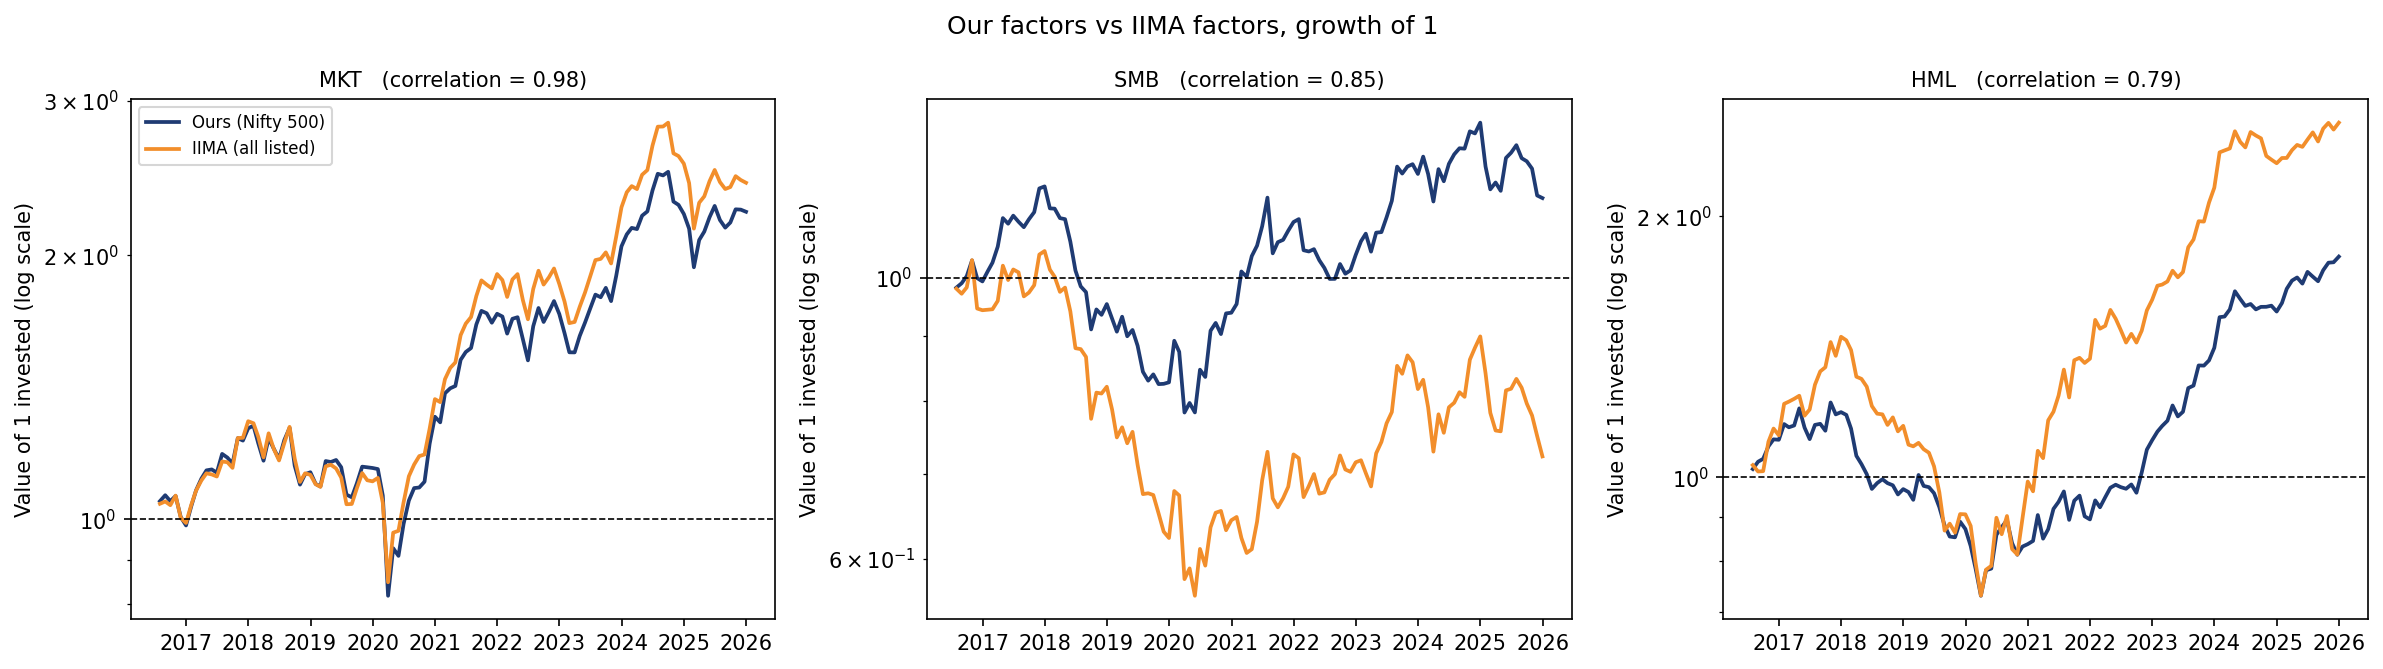

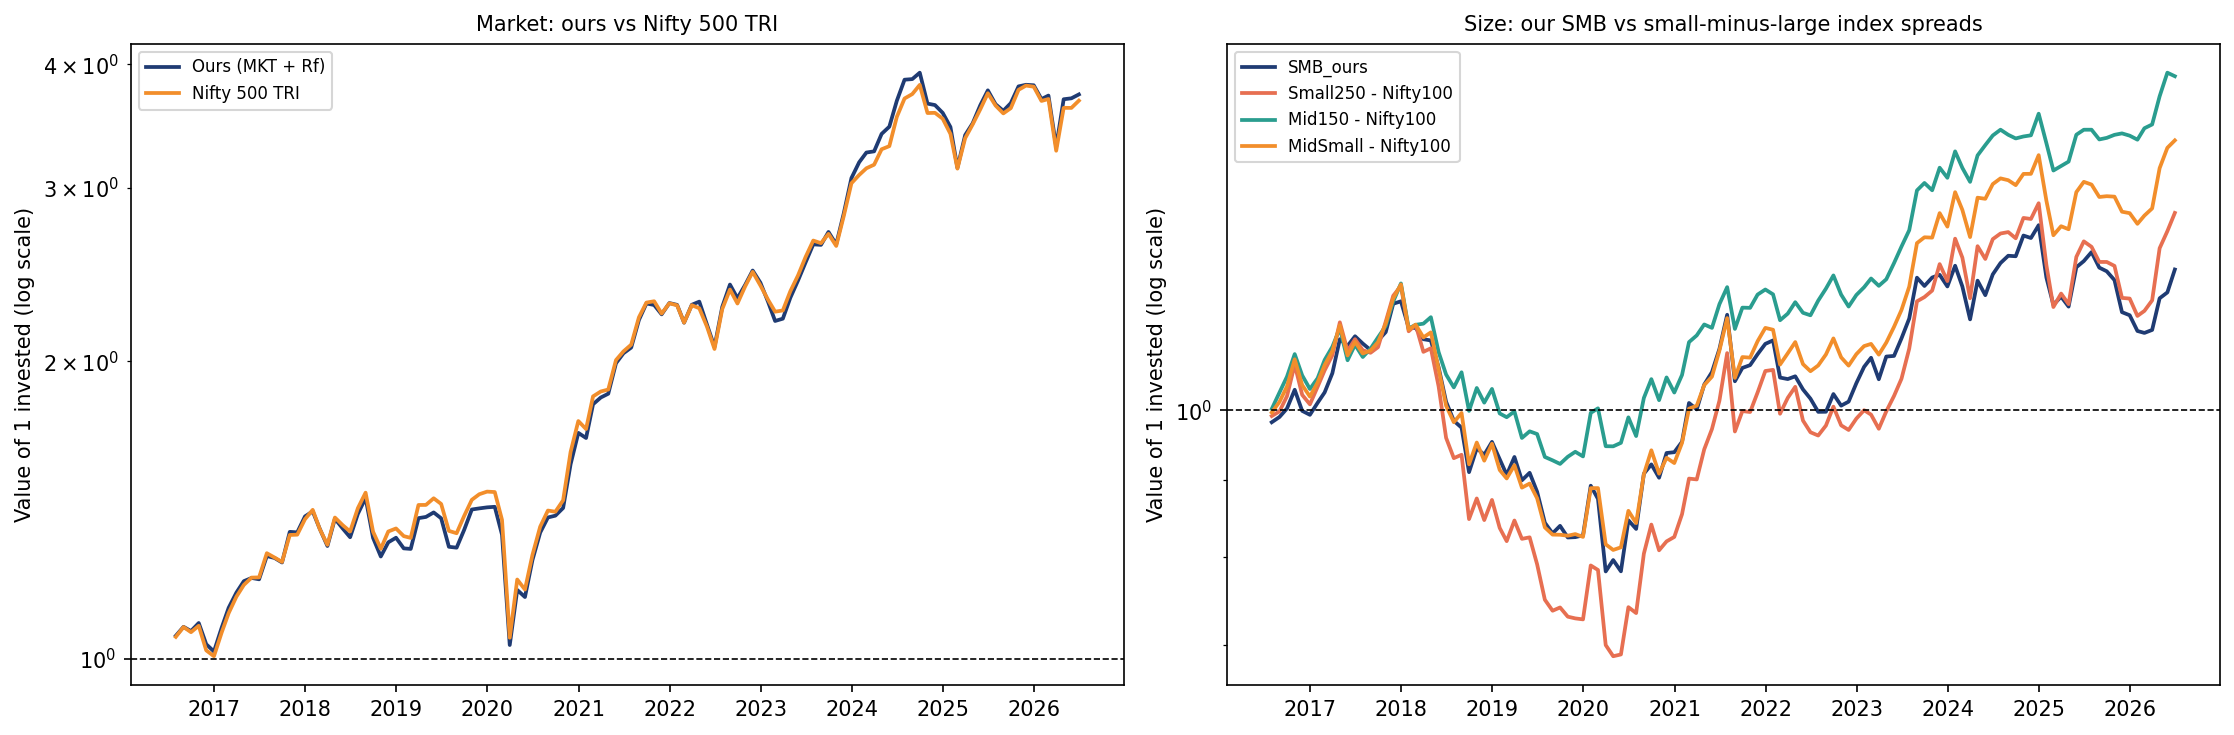

In [17]:
# 2.7 Plots - growth of 1: ours vs IIMA, and ours vs NSE indices

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=150)
for ax, col in zip(axes, ["MKT", "SMB", "HML"]):
    ax.plot((1 + ours[col]).cumprod(), color="#1f3b73", linewidth=1.8, label="Ours (Nifty 500)")
    ax.plot((1 + theirs[col]).cumprod(), color="#f28e2b", linewidth=1.8, label="IIMA (all listed)")
    ax.set_yscale("log")
    ax.axhline(1, color="black", linewidth=0.8, linestyle="--")
    ax.set_title(f"{col}   (correlation = {validation.loc[col, 'correlation']:.2f})", fontsize=10)
    ax.set_ylabel("Value of 1 invested (log scale)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Our factors vs IIMA factors, growth of 1", fontsize=12)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "2_7a_ours_vs_iima.png", bbox_inches="tight", dpi=300)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=150)
axes[0].plot((1 + m["ours"]).cumprod(), color="#1f3b73", linewidth=1.8, label="Ours (MKT + Rf)")
axes[0].plot((1 + m["nifty500_tri"]).cumprod(), color="#f28e2b", linewidth=1.8, label="Nifty 500 TRI")
axes[0].set_title("Market: ours vs Nifty 500 TRI", fontsize=10)
spread_colors = {"SMB_ours": "#1f3b73", "Small250 - Nifty100": "#e76f51",
                 "Mid150 - Nifty100": "#2a9d8f", "MidSmall - Nifty100": "#f28e2b"}
for col, color in spread_colors.items():
    axes[1].plot((1 + spreads[col]).cumprod(), color=color, linewidth=1.8, label=col)
axes[1].set_title("Size: our SMB vs small-minus-large index spreads", fontsize=10)
for ax in axes:
    ax.set_yscale("log")
    ax.axhline(1, color="black", linewidth=0.8, linestyle="--")
    ax.set_ylabel("Value of 1 invested (log scale)")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "2_7b_index_checks.png", bbox_inches="tight", dpi=300)
plt.show()

In [18]:
# 2.8 Save

validation.to_csv(OUTPUT_DIR / "phase_4_external_validation.csv")
market_check.to_frame().to_csv(OUTPUT_DIR / "phase_4_market_index_check.csv")
smb_check.to_csv(OUTPUT_DIR / "phase_4_smb_index_check.csv")
v1_vs_v2_validation.to_csv(OUTPUT_DIR / "phase_4_v1_vs_v2_validation.csv", index=False)
tri_monthly.to_csv(OUTPUT_DIR / "phase_4_nse_tri_monthly.csv")
iima.to_csv(OUTPUT_DIR / "phase_4_iima_factors.csv")
print("Saved: external validation, market and SMB index checks, v1 vs v2 table, TRI and IIMA monthly series")

Saved: external validation, market and SMB index checks, v1 vs v2 table, TRI and IIMA monthly series


## Inferences: External validation

*IIMA: 114 overlapping months (Jul-2016 to Dec-2025). NSE TRI: 120 months (Jul-2016 to Jun-2026; the TRI files end in Jun-2026).*

**1. Every factor passes on construction against IIMA.**

| Factor | Correlation v1 → v2 | Ours, monthly % (NW t) | IIMA, monthly % (NW t) | Gap (NW t) |
|---|---|---|---|---|
| MKT | 0.95 → **0.98** | 0.83 (1.92) | 0.89 (1.99) | −0.06 (−0.61) |
| SMB | 0.77 → **0.85** | 0.18 (0.58) | −0.20 (−0.56) | +0.38 (1.91) |
| HML | 0.73 → **0.79** | 0.57 (1.66) | 0.93 (1.83) | −0.36 (−1.11) |
| Rf | 0.96 | 0.47 | 0.46 | +0.01 |

- **SMB:** the v1 gap of 1.44% a month (t = 5.6) is down to 0.38% (t = 1.9), no longer significant at 5%. The remaining gap fits the universe difference: IIMA's small stocks are far smaller than the bottom half of the top 500.
- **HML:** ours is lower than IIMA's (0.57% vs 0.93%), but not significantly. The value premium is stronger outside the Nifty 500.
- **Same conclusions as IIMA:** neither source has a factor significant at 5% over this period (premium verdicts: all Pass).

**2. The market return now matches the Nifty 500 TRI.**
CAGR 14.06% vs 13.90% (v1: 9.82% vs 13.90%); correlation 0.992; tracking error 2.09% a year (v1: 4.61%); average gap 0.01% a month (t = 0.23). The remaining tracking error comes from full vs free-float weights.

**3. SMB matches the survivorship-free index spreads.**

| Series | Annual % | NW t | Correlation with our SMB | Gap vs our SMB, monthly % (NW t) |
|---|---|---|---|---|
| Our SMB | 2.80 | 0.76 | – | – |
| Smallcap 250 − Nifty 100 | 3.97 | 0.85 | 0.94 | −0.10 (−0.71) |
| Midcap 150 − Nifty 100 | 5.52 | **2.05** | 0.82 | −0.23 (−1.39) |
| (Mid + Small)/2 − Nifty 100 | 4.75 | 1.31 | 0.92 | −0.16 (−1.39) |

- In v1 our SMB earned 15.6% a year against 4.75% for the spread; it now earns 2.8%, with no significant gap.
- Our SMB is a little below the spreads because it is value-, profitability- and investment-neutral and uses full-cap weights; the index spreads are neither.
- **Midcap 150 − Nifty 100 is the only significant spread (t = 2.05).** Mid-caps beat large caps over the decade, the same effect as Phase 3's positive Mid-row intercepts.

**Conclusion:** the corrected data and factor construction are validated externally. Survivorship bias is gone; RMW and CMA have no external benchmark and are checked internally in Step 3.

## Step 3: Alternative factor constructions

The five factors are rebuilt from the Phase 2 files with **one choice changed at a time**. The test portfolios stay the Phase 3 ones, so every change in the results comes from the factors.

| Version | What changes | Why it matters in India |
|---|---|---|
| Baseline (rebuilt) | Nothing; must reproduce `phase_2_ff5_factors.csv` exactly | Proves the rebuild uses the Phase 2 recipe |
| 2×2 sorts | Characteristic split at the Big-stock median instead of 30/70 | FF (2015) robustness version; every stock in a long or short leg |
| Excl. financials | Banks, NBFCs, insurers dropped from the SMB, HML, RMW and CMA sorts (MKT unchanged) | Financials are about a quarter of market cap and have different balance sheets |
| Big = top 100 | Big = 100 largest stocks each June (Nifty 100 analog), Small = the rest | Indian analog of FF's NYSE breakpoints; tests whether Phase 3's mid-cap intercepts come from the median split |
| Equal-weighted | Equal weights in every factor portfolio, MKT included | Diagnostic only: shows how much of each premium sits in smaller stocks |

**Reported for each version:** premia with verdicts against the baseline, correlation with the baseline factor, spanning intercepts (is HML still redundant?), and GRS, A|a| and the Mid-row intercept for FF3 and FF5 on the Phase 3 test portfolios.

In [19]:
# 3.1 Factor builder: the Phase 2 recipe, with one switch per alternative

CHAR_SORTS = {                    # factor: (sort variable, sign of high-minus-low)
    "HML": ("bm", +1),            # high B/M (value) minus low B/M (growth)
    "RMW": ("op", +1),            # high OP (robust) minus low OP (weak)
    "CMA": ("inv", -1),           # low investment (conservative) minus high (aggressive)
}


def portfolio_returns(labels, weighting="VW"):
    """Monthly return of each portfolio (column PORT), held July t to June t+1.
    VW weights = last month's ME. Portfolio-months with fewer than MIN_STOCKS stocks are NaN (Phase 2 rule)."""
    df = panel_df.merge(labels, on=["symbol", "formation_date"], how="inner")
    df = df[df["me_lag"] > 0].copy()
    df["w"] = df["me_lag"] if weighting == "VW" else 1.0
    df["w_ret"] = df["w"] * df["ret"]
    g = df.groupby(["date", "PORT"]).agg(w_ret=("w_ret", "sum"), w=("w", "sum"), n=("symbol", "count"))
    ret = (g["w_ret"] / g["w"]).where(g["n"] >= MIN_STOCKS)
    return ret.unstack("PORT")


def build_factors(sort="2x3", size_rule="median", drop_financials=False, weighting="VW"):
    """
    Rebuild MKT, SMB, HML, RMW, CMA. The defaults are the Phase 2 choices.
    sort:            "2x3" (30/70) or "2x2" (median) characteristic breakpoints, from Big stocks
    size_rule:       "median" (Phase 2 SIZE) or "top100" (Big = TOP_N_BIG largest stocks each June)
    drop_financials: drop financial firms from the SMB, HML, RMW and CMA sorts (MKT unchanged)
    weighting:       "VW" (value) or "EW" (equal), for every factor portfolio including MKT
    """
    form = formation_df[formation_df["formation_date"].isin(FORMATIONS_USED)].copy()

    # Size label, set on all stocks before any are dropped (one change at a time)
    if size_rule == "top100":
        rank = form.groupby("formation_date")["me_june"].rank(ascending=False, method="first")
        form["SIZE"] = np.where(rank <= TOP_N_BIG, "B", "S")
    if drop_financials:
        form = form[~form["is_financial"]]

    # Phase 2 eligibility for each sort
    eligible = {
        "HML": form[(form["book_value"] > 0) & (form["bm"] > 0)],
        "RMW": form[(form["book_value"] > 0) & form["op"].notna()],
        "CMA": form[form["inv"].notna()],
    }
    q_low, q_high = (BP_LOW, BP_HIGH) if sort == "2x3" else (0.5, 0.5)
    char_groups = ["L", "N", "H"] if sort == "2x3" else ["L", "H"]

    factors, size_spreads = {}, []
    for name, (var, sign) in CHAR_SORTS.items():
        df = eligible[name].copy()

        # Characteristic breakpoints from the Big stocks of each June, applied to all stocks
        big = df[df["SIZE"] == "B"].groupby("formation_date")[var]
        low = df["formation_date"].map(big.quantile(q_low))
        high = df["formation_date"].map(big.quantile(q_high))
        df["CHAR"] = "N"
        df.loc[df[var] <= low, "CHAR"] = "L"
        df.loc[df[var] >= high, "CHAR"] = "H"
        df["PORT"] = df["SIZE"] + df["CHAR"]

        ports = portfolio_returns(df[["symbol", "formation_date", "PORT"]], weighting)
        ports = ports.reindex(columns=[s + c for s in "SB" for c in char_groups])

        high_minus_low = (ports[["SH", "BH"]].mean(axis=1, skipna=False)
                          - ports[["SL", "BL"]].mean(axis=1, skipna=False))
        factors[name] = sign * high_minus_low
        size_spreads.append(ports[["S" + c for c in char_groups]].mean(axis=1, skipna=False)
                            - ports[["B" + c for c in char_groups]].mean(axis=1, skipna=False))

    factors["SMB"] = pd.concat(size_spreads, axis=1).mean(axis=1, skipna=False)

    # Market: every universe stock, financials always included
    mkt = panel_df[panel_df["me_lag"] > 0].copy()
    mkt["w"] = mkt["me_lag"] if weighting == "VW" else 1.0
    mkt["w_ret"] = mkt["w"] * mkt["ret"]
    g = mkt.groupby("date")
    factors["Rf"] = g["Rf_monthly"].first()
    factors["MKT"] = g["w_ret"].sum() / g["w"].sum() - factors["Rf"]

    out = pd.DataFrame(factors)[FACTOR_COLS + ["Rf"]].dropna().sort_index()
    out.index.name = "date"
    return out

In [20]:
# 3.2 The rebuilt baseline must reproduce the Phase 2 factors exactly

rebuilt = build_factors()
gap = (rebuilt - df_factors).abs().max().max()
print("Months:", len(rebuilt), "vs", len(df_factors), "| largest difference:", f"{gap:.1e}")
assert rebuilt.index.equals(df_factors.index) and gap < 1e-10, "Rebuild differs from Phase 2: check before going on"

Months: 123 vs 123 | largest difference: 9.9e-17


In [21]:
# 3.3 Build the alternative versions (one change each)

VERSIONS = {
    "Baseline":         {},
    "2x2 sorts":        {"sort": "2x2"},
    "Excl. financials": {"drop_financials": True},
    "Big = top 100":    {"size_rule": "top100"},
    "Equal-weighted":   {"weighting": "EW"},
}

alt_factors = {name: build_factors(**options) for name, options in VERSIONS.items()}
for name, f in alt_factors.items():
    print(f"{name:18s} months: {len(f)} | {f.index.min().date()} -> {f.index.max().date()}")

Baseline           months: 123 | 2016-07-31 -> 2026-09-30
2x2 sorts          months: 123 | 2016-07-31 -> 2026-09-30
Excl. financials   months: 123 | 2016-07-31 -> 2026-09-30
Big = top 100      months: 123 | 2016-07-31 -> 2026-09-30
Equal-weighted     months: 123 | 2016-07-31 -> 2026-09-30


In [22]:
# 3.4 Factor premia under each version, with verdicts against the baseline

rows = []
for name, f in alt_factors.items():
    prem = factor_premia(f[FACTOR_COLS])
    for factor in FACTOR_COLS:
        base = baseline_factors.loc[factor]
        new = prem.loc[factor]
        rows.append({
            "version": name, "factor": factor,
            "mean_monthly_%": new["mean_monthly_%"],
            "mean_annual_%": new["mean_annual_%"],
            "t_stat_nw": new["t_stat_nw"],
            "corr_with_baseline": f[factor].corr(df_factors[factor]),
            "verdict": premium_verdict(base["mean_monthly_%"], base["t_stat_nw"],
                                       new["mean_monthly_%"], new["t_stat_nw"]),
        })
alt_premia = pd.DataFrame(rows)

for value in ["mean_annual_%", "t_stat_nw", "corr_with_baseline", "verdict"]:
    print(value)
    table = alt_premia.pivot(index="factor", columns="version", values=value).loc[FACTOR_COLS, list(VERSIONS)]
    display(table.round(2) if value != "verdict" else table)

mean_annual_%


version,Baseline,2x2 sorts,Excl. financials,Big = top 100,Equal-weighted
factor,,,,,
MKT,8.41,8.41,8.41,8.41,10.55
SMB,2.80,3.07,2.49,3.61,0.00
HML,6.38,4.68,6.60,5.67,6.05
RMW,-1.74,-3.60,-1.74,-4.08,-1.81
CMA,1.15,-0.05,2.58,-0.64,1.24


t_stat_nw


version,Baseline,2x2 sorts,Excl. financials,Big = top 100,Equal-weighted
factor,,,,,
MKT,1.70,1.70,1.70,1.70,1.55
SMB,0.78,0.83,0.69,1.19,0.00
HML,1.64,1.87,1.78,1.31,1.36
RMW,-0.73,-2.15,-0.73,-1.89,-0.71
CMA,0.45,-0.02,1.09,-0.23,0.61


corr_with_baseline


version,Baseline,2x2 sorts,Excl. financials,Big = top 100,Equal-weighted
factor,,,,,
MKT,1.0,1.00,1.00,1.00,0.94
SMB,1.0,1.00,0.99,0.94,0.90
HML,1.0,0.94,0.92,0.94,0.93
RMW,1.0,0.90,1.00,0.86,0.85
CMA,1.0,0.90,0.88,0.92,0.76


verdict


version,Baseline,2x2 sorts,Excl. financials,Big = top 100,Equal-weighted
factor,,,,,
MKT,Pass,Pass,Pass,Pass,Pass
SMB,Pass,Pass,Pass,Pass,Pass
HML,Pass,Pass,Pass,Pass,Pass
RMW,Pass,Fragile,Pass,Pass,Pass
CMA,Pass,Pass,Pass,Pass,Pass


In [23]:
# 3.5 Spanning regressions under each version: each factor on the other four (Newey-West t)

def spanning(factors):
    rows = {}
    for factor in FACTOR_COLS:
        others = [f for f in FACTOR_COLS if f != factor]
        fit = sm.OLS(factors[factor], sm.add_constant(factors[others])).fit(
            cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
        rows[factor] = {"intercept_monthly_%": fit.params["const"] * 100,
                        "t_nw": fit.tvalues["const"], "r_squared": fit.rsquared}
    out = pd.DataFrame(rows).T
    out.index.name = "factor"
    return out

alt_spanning = pd.concat({name: spanning(f) for name, f in alt_factors.items()}, names=["version"]).reset_index()
alt_spanning["adds_information"] = alt_spanning["t_nw"].abs() > T_CRIT

# The baseline must match Phase 3's spanning table
gap = (spanning(df_factors).loc[FACTOR_COLS, "t_nw"] - spanning_p3.loc[FACTOR_COLS, "t_intercept_nw"]).abs().max()
print(f"Baseline spanning t vs Phase 3, largest difference: {gap:.1e}")

display(alt_spanning.pivot(index="factor", columns="version", values="intercept_monthly_%").loc[FACTOR_COLS, list(VERSIONS)].round(3))
display(alt_spanning.pivot(index="factor", columns="version", values="t_nw").loc[FACTOR_COLS, list(VERSIONS)].round(2))

Baseline spanning t vs Phase 3, largest difference: 1.1e-16


version,Baseline,2x2 sorts,Excl. financials,Big = top 100,Equal-weighted
factor,,,,,
MKT,0.373,0.290,0.445,0.337,0.507
SMB,0.016,-0.044,-0.027,0.109,-0.217
HML,0.231,0.116,0.202,0.018,0.194
RMW,0.130,-0.067,0.097,-0.097,0.072
CMA,0.045,-0.018,0.153,0.014,-0.030


version,Baseline,2x2 sorts,Excl. financials,Big = top 100,Equal-weighted
factor,,,,,
MKT,0.99,0.74,1.27,0.86,1.53
SMB,0.07,-0.17,-0.10,0.50,-1.50
HML,1.06,0.78,0.99,0.07,0.98
RMW,0.81,-0.55,0.56,-0.63,0.57
CMA,0.25,-0.12,0.91,0.07,-0.27


In [24]:
# 3.6 FF3 and FF5 with each version's factors, on the Phase 3 test portfolios

TEST_MODELS = {m: MODELS[m] for m in ["FF3", "FF5"]}
base_p = baseline_models.set_index(["model", "sort_type"])["p_value"]

rows, mid_rows = [], []
for name, f in alt_factors.items():
    months = excess_wide.index.intersection(f.index)
    table, ports = evaluate_models(excess_wide.loc[months], f.loc[months], TEST_MODELS, TEST_SETS)
    rows.append(table.assign(version=name, n_months=len(months)))
    mid_a, mid_sig = mid_row_alpha(ports)
    mid_rows.append({"version": name, "FF5_mid_row_avg_a_%": mid_a, "FF5_mid_row_significant": mid_sig})

alt_models = pd.concat(rows, ignore_index=True)
alt_models["verdict"] = [grs_verdict(base_p[(m, s)], p)
                         for m, s, p in zip(alt_models["model"], alt_models["sort_type"], alt_models["p_value"])]
alt_mid = pd.DataFrame(mid_rows)

ff5_tests = alt_models[alt_models["model"] == "FF5"]
for value in ["GRS", "p_value", "verdict"]:
    print("FF5", value)
    display(ff5_tests.pivot(index="sort_type", columns="version", values=value)[list(VERSIONS)].round(3))
    
print("A|a|, monthly %")
display(alt_models.pivot_table(index=["model", "sort_type"], columns="version", values="avg_abs_a")[list(VERSIONS)].round(3))
display(alt_mid.round(3))

FF5 GRS


version,Baseline,2x2 sorts,Excl. financials,Big = top 100,Equal-weighted
sort_type,,,,,
ALL,1.386,1.559,1.529,1.868,1.404
BM,2.082,2.155,2.265,1.969,2.562
INV,0.981,0.561,1.554,0.683,0.886
OP,1.712,1.793,1.720,1.667,1.713


FF5 p_value


version,Baseline,2x2 sorts,Excl. financials,Big = top 100,Equal-weighted
sort_type,,,,,
ALL,0.128,0.062,0.071,0.015,0.120
BM,0.037,0.031,0.023,0.050,0.010
INV,0.460,0.826,0.138,0.723,0.541
OP,0.095,0.078,0.093,0.106,0.094


FF5 verdict


version,Baseline,2x2 sorts,Excl. financials,Big = top 100,Equal-weighted
sort_type,,,,,
ALL,Pass,Pass,Pass,Fragile,Pass
BM,Pass,Pass,Pass,Pass,Pass
INV,Pass,Pass,Pass,Pass,Pass
OP,Pass,Pass,Pass,Pass,Pass


A|a|, monthly %


version          Baseline  2x2 sorts  Excl. financials  Big = top 100  \
model sort_type                                                         
FF3   ALL           0.130      0.132             0.134          0.132   
      BM            0.145      0.150             0.147          0.159   
      INV           0.092      0.086             0.109          0.084   
      OP            0.152      0.159             0.146          0.152   
FF5   ALL           0.141      0.135             0.153          0.135   
      BM            0.146      0.151             0.150          0.163   
      INV           0.108      0.086             0.146          0.089   
      OP            0.168      0.169             0.164          0.152   

version          Equal-weighted  
model sort_type                  
FF3   ALL                 0.147  
      BM                  0.174  
      INV                 0.126  
      OP                  0.142  
FF5   ALL                 0.155  
      BM                  0.175  
      INV                 0.132  
      OP                  0.158

,version,FF5_mid_row_avg_a_%,FF5_mid_row_significant
0,Baseline,0.174,4
1,2x2 sorts,0.144,2
2,Excl. financials,0.205,4
3,Big = top 100,0.074,2
4,Equal-weighted,0.167,3


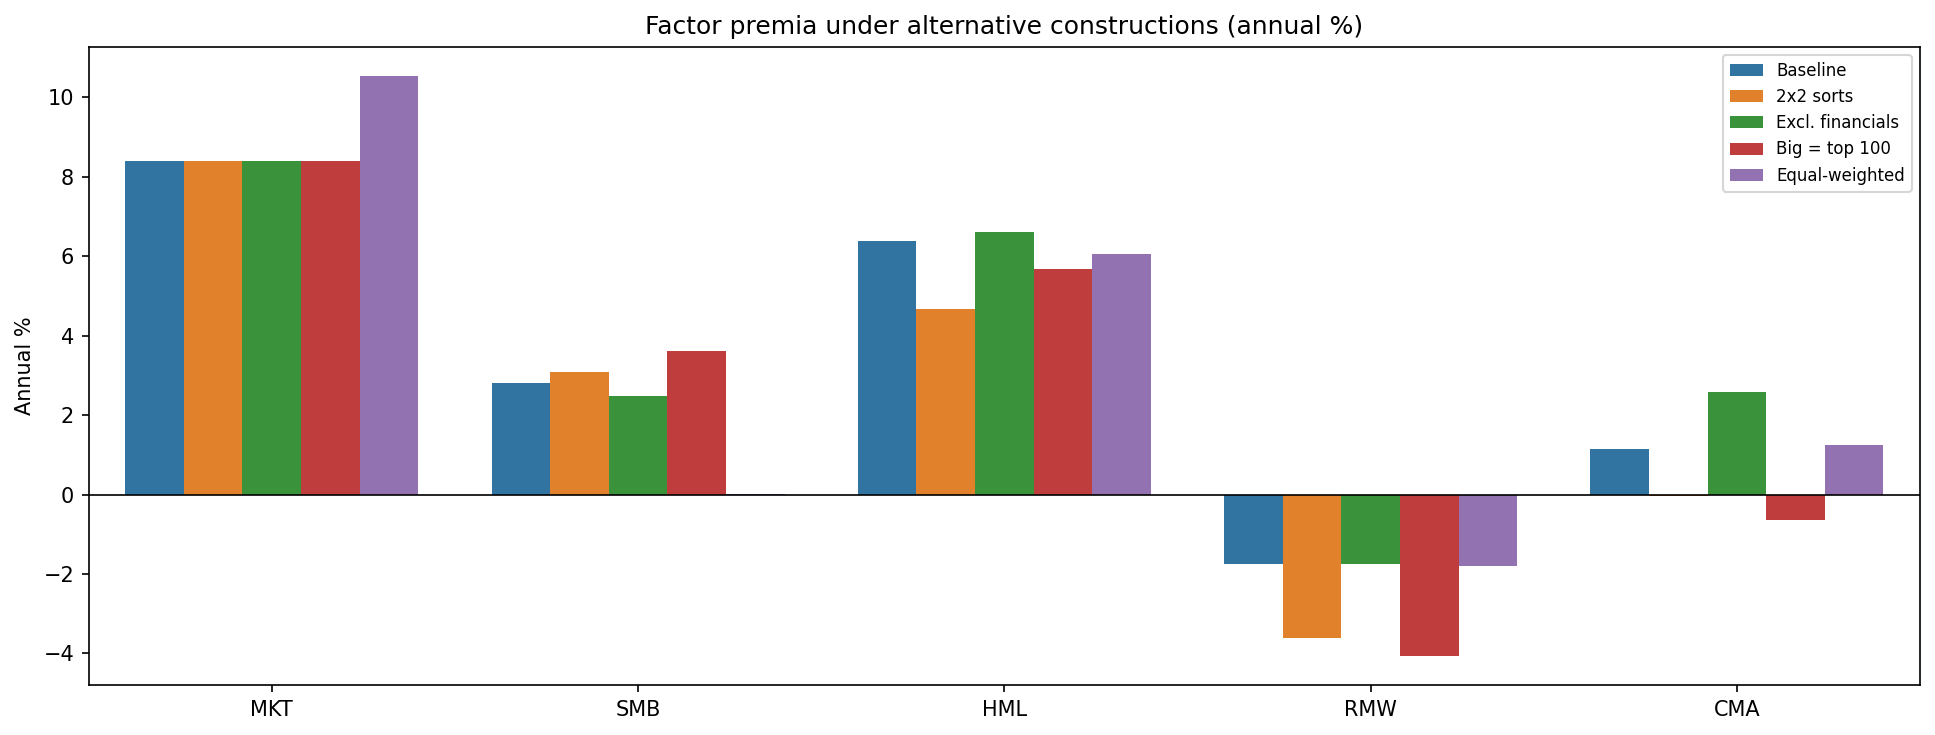

In [25]:
# 3.7 Plot - annual premium of each factor under each version

fig, ax = plt.subplots(figsize=(13, 5), dpi=150)
sns.barplot(data=alt_premia, x="factor", y="mean_annual_%", hue="version",
            order=FACTOR_COLS, hue_order=list(VERSIONS), ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Factor premia under alternative constructions (annual %)")
ax.set_xlabel("")
ax.set_ylabel("Annual %")
ax.legend(title="", fontsize=8)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "3_7_alternative_premia.png", bbox_inches="tight", dpi=300)
plt.show()

In [26]:
# 3.8 Save

pd.concat(alt_factors, names=["version"]).reset_index().to_csv(OUTPUT_DIR / "phase_4_alt_factors.csv", index=False)
alt_premia.to_csv(OUTPUT_DIR / "phase_4_alt_premia.csv", index=False)
alt_spanning.to_csv(OUTPUT_DIR / "phase_4_alt_spanning.csv", index=False)
alt_models.to_csv(OUTPUT_DIR / "phase_4_alt_models.csv", index=False)
alt_mid.to_csv(OUTPUT_DIR / "phase_4_alt_mid_row.csv", index=False)
print("Saved: alternative factors, premia, spanning, model tests, Mid-row intercepts")

Saved: alternative factors, premia, spanning, model tests, Mid-row intercepts


## Inferences: Alternative factor constructions

*The rebuilt baseline reproduces the Phase 2 factors exactly (largest difference 1e-16). Correlations with the baseline factors are 0.85–1.00, except CMA when equal-weighted (0.76).*

**1. Premia: 19 of 20 verdicts Pass.**

| Factor | Annual % across the four alternatives | NW t range | Verdict |
|---|---|---|---|
| MKT | 8.4 (VW), 10.6 (EW) | 1.55 to 1.70 | Pass |
| SMB | 2.5 to 3.6 (EW 0.0) | 0.00 to 1.19 | Pass |
| HML | 4.7 to 6.6 | 1.31 to 1.87 | Pass |
| RMW | −1.7 to −4.1 | −0.71 to **−2.15** | Fragile (2×2 sorts) |
| CMA | −0.6 to 2.6 | −0.23 to 1.09 | Pass |

- **HML** stays positive (4.7–6.6% a year) and insignificant in every version.
- **RMW** is negative in every version and becomes significantly negative with 2×2 sorts (−3.6% a year, t = −2.15); with Big = top 100 it is −4.1% (t = −1.89). The negative profitability premium is real in sign; only its size is uncertain.
- **SMB is zero when equal-weighted.** The value-weighted size premium comes from the larger names in the Small half (mid-caps), not from the smallest stocks.
- **Equal-weighted MKT beats value-weighted by about 2% a year** (10.6% vs 8.4%): the average Nifty 500 stock did better than the largest ones.
- **CMA rises to 2.6% a year without financials** (t = 1.09). For banks and NBFCs asset growth is loan growth, not capex, so they dilute the investment factor.

**2. Spanning: no factor has a significant intercept in any version** (largest |t| = 1.53). HML stays redundant everywhere (t from 0.07 to 1.06); with Big = top 100 its intercept is almost exactly zero (0.02% a month).

**3. Model tests**

| FF5 GRS (p) | Baseline | 2×2 | Excl. fin. | Big = top 100 | EW |
|---|---|---|---|---|---|
| B/M | 2.08 (0.037) | 2.16 (0.031) | 2.27 (0.023) | 1.97 (0.050) | 2.56 (0.010) |
| All 27 | 1.39 (0.128) | 1.56 (0.062) | 1.53 (0.071) | **1.87 (0.015)** | 1.40 (0.120) |

- FF5's B/M rejection holds in every version (with Big = top 100 it is exactly at the 5% line).
- **Big = top 100** is the only Fragile case: FF5 is also rejected on all 27 portfolios, and FF3 is no longer rejected on B/M.
- **FF5 never beats FF3:** A|a| on all portfolios is 0.135–0.155% for FF5 against 0.130–0.147% for FF3.

**4. Mid-cap intercept: positive in every version, but about 60% of it comes from the median size split.**

| | Baseline | 2×2 | Excl. fin. | Big = top 100 | EW |
|---|---|---|---|---|---|
| FF5 Mid-row average a, % | 0.17 | 0.14 | 0.21 | **0.07** | 0.17 |
| Significant (of 9) | 4 | 2 | 4 | 2 | 3 |

With Big = the top 100, mid-caps move into SMB's long side. SMB becomes "mid + small minus large" (3.6% a year), and the Mid-row intercept falls from 0.17% to 0.07%. Part of the mid-cap alpha is therefore a construction effect: a median split puts the best-performing mid-caps on the Big side.

## Step 4: Time stability

Phase 3 showed every factor premium changing sign around 2021. The baseline tests are rerun on:
- **First half:** Jul-2016 to Jun-2021 (60 months)
- **Second half:** Jul-2021 to the latest month
- **Excl. Covid:** the full sample without Mar–Jun 2020 (crash and first rebound)

Verdicts compare each period with the full sample. With about 60 months in a half, GRS has little power, so a changed verdict is a warning, not a finding.

In [27]:
# 4.1 Sample periods, and factor premia in each

PERIODS = {
    "Full sample": df_factors.index,
    "First half":  df_factors.index[df_factors.index <= SPLIT_DATE],
    "Second half": df_factors.index[df_factors.index > SPLIT_DATE],
    "Excl. Covid": df_factors.index[~df_factors.index.isin(COVID_MONTHS)],
}
print({name: len(months) for name, months in PERIODS.items()})

rows = []
for name, months in PERIODS.items():
    prem = factor_premia(df_factors.loc[months, FACTOR_COLS])
    for factor in FACTOR_COLS:
        base, new = baseline_factors.loc[factor], prem.loc[factor]
        rows.append({
            "period": name, "factor": factor, "n_months": len(months),
            "mean_monthly_%": new["mean_monthly_%"], "mean_annual_%": new["mean_annual_%"],
            "t_stat_nw": new["t_stat_nw"],
            "verdict": premium_verdict(base["mean_monthly_%"], base["t_stat_nw"],
                                       new["mean_monthly_%"], new["t_stat_nw"]),
        })
period_premia = pd.DataFrame(rows)

for value in ["mean_annual_%", "t_stat_nw", "verdict"]:
    print(value)
    table = period_premia.pivot(index="factor", columns="period", values=value).loc[FACTOR_COLS, list(PERIODS)]
    display(table.round(2) if value != "verdict" else table)

{'Full sample': 123, 'First half': 60, 'Second half': 63, 'Excl. Covid': 119}
mean_annual_%


period,Full sample,First half,Second half,Excl. Covid
factor,,,,
MKT,8.41,10.63,6.30,9.01
SMB,2.80,2.58,3.02,3.13
HML,6.38,-0.46,12.90,5.60
RMW,-1.74,2.88,-6.15,-0.99
CMA,1.15,-1.04,3.23,0.70


t_stat_nw


period,Full sample,First half,Second half,Excl. Covid
factor,,,,
MKT,1.70,1.37,1.06,1.99
SMB,0.78,0.43,0.75,0.85
HML,1.64,-0.08,3.02,1.37
RMW,-0.73,1.12,-1.83,-0.37
CMA,0.45,-0.35,0.83,0.26


verdict


period,Full sample,First half,Second half,Excl. Covid
factor,,,,
MKT,Pass,Pass,Pass,Pass
SMB,Pass,Pass,Pass,Pass
HML,Pass,Pass,Fragile,Pass
RMW,Pass,Pass,Pass,Pass
CMA,Pass,Pass,Pass,Pass


In [28]:
# 4.2 Model tests and spanning regressions in each period

rows, mid_rows, span_rows = [], [], []
for name, months in PERIODS.items():
    table, ports = evaluate_models(excess_wide.loc[months], df_factors.loc[months, FACTOR_COLS], MODELS, TEST_SETS)
    rows.append(table.assign(period=name, n_months=len(months)))
    mid_a, mid_sig = mid_row_alpha(ports)
    mid_rows.append({"period": name, "FF5_mid_row_avg_a_%": mid_a, "FF5_mid_row_significant": mid_sig})
    span_rows.append(spanning(df_factors.loc[months, FACTOR_COLS]).assign(period=name).reset_index())

period_models = pd.concat(rows, ignore_index=True)
period_models["verdict"] = [grs_verdict(base_p[(m, s)], p)
                            for m, s, p in zip(period_models["model"], period_models["sort_type"], period_models["p_value"])]
period_mid = pd.DataFrame(mid_rows)
period_spanning = pd.concat(span_rows, ignore_index=True)

ff5_periods = period_models[period_models["model"] == "FF5"]
for value in ["GRS", "p_value", "verdict"]:
    print("FF5", value)
    display(ff5_periods.pivot(index="sort_type", columns="period", values=value)[list(PERIODS)].round(3))
print("A|a| on all portfolios, monthly %")
display(period_models[period_models["sort_type"] == "ALL"]
        .pivot(index="model", columns="period", values="avg_abs_a").loc[list(MODELS), list(PERIODS)].round(3))
print("Spanning intercept t (Newey-West)")
display(period_spanning.pivot(index="factor", columns="period", values="t_nw").loc[FACTOR_COLS, list(PERIODS)].round(2))
display(period_mid.round(3))

FF5 GRS


period,Full sample,First half,Second half,Excl. Covid
sort_type,,,,
ALL,1.386,1.141,0.817,1.187
BM,2.082,1.638,1.462,1.654
INV,0.981,1.135,2.098,0.683
OP,1.712,2.685,0.651,1.629


FF5 p_value


period,Full sample,First half,Second half,Excl. Covid
sort_type,,,,
ALL,0.128,0.365,0.702,0.271
BM,0.037,0.133,0.189,0.109
INV,0.460,0.359,0.048,0.723
OP,0.095,0.013,0.748,0.116


FF5 verdict


period,Full sample,First half,Second half,Excl. Covid
sort_type,,,,
ALL,Pass,Pass,Pass,Pass
BM,Pass,Fragile,Fragile,Fragile
INV,Pass,Pass,Fragile,Pass
OP,Pass,Fragile,Pass,Pass


A|a| on all portfolios, monthly %


period,Full sample,First half,Second half,Excl. Covid
model,,,,
CAPM,0.166,0.232,0.317,0.150
FF3,0.130,0.213,0.227,0.123
FF4_noHML,0.135,0.228,0.207,0.125
FF5,0.141,0.233,0.227,0.123


Spanning intercept t (Newey-West)


period,Full sample,First half,Second half,Excl. Covid
factor,,,,
MKT,0.99,1.47,0.71,1.54
SMB,0.07,0.20,0.04,0.35
HML,1.06,-0.66,2.08,1.24
RMW,0.81,0.92,0.01,1.22
CMA,0.25,1.00,-0.21,-0.19


,period,FF5_mid_row_avg_a_%,FF5_mid_row_significant
0,Full sample,0.174,4
1,First half,0.208,3
2,Second half,0.220,2
3,Excl. Covid,0.150,2


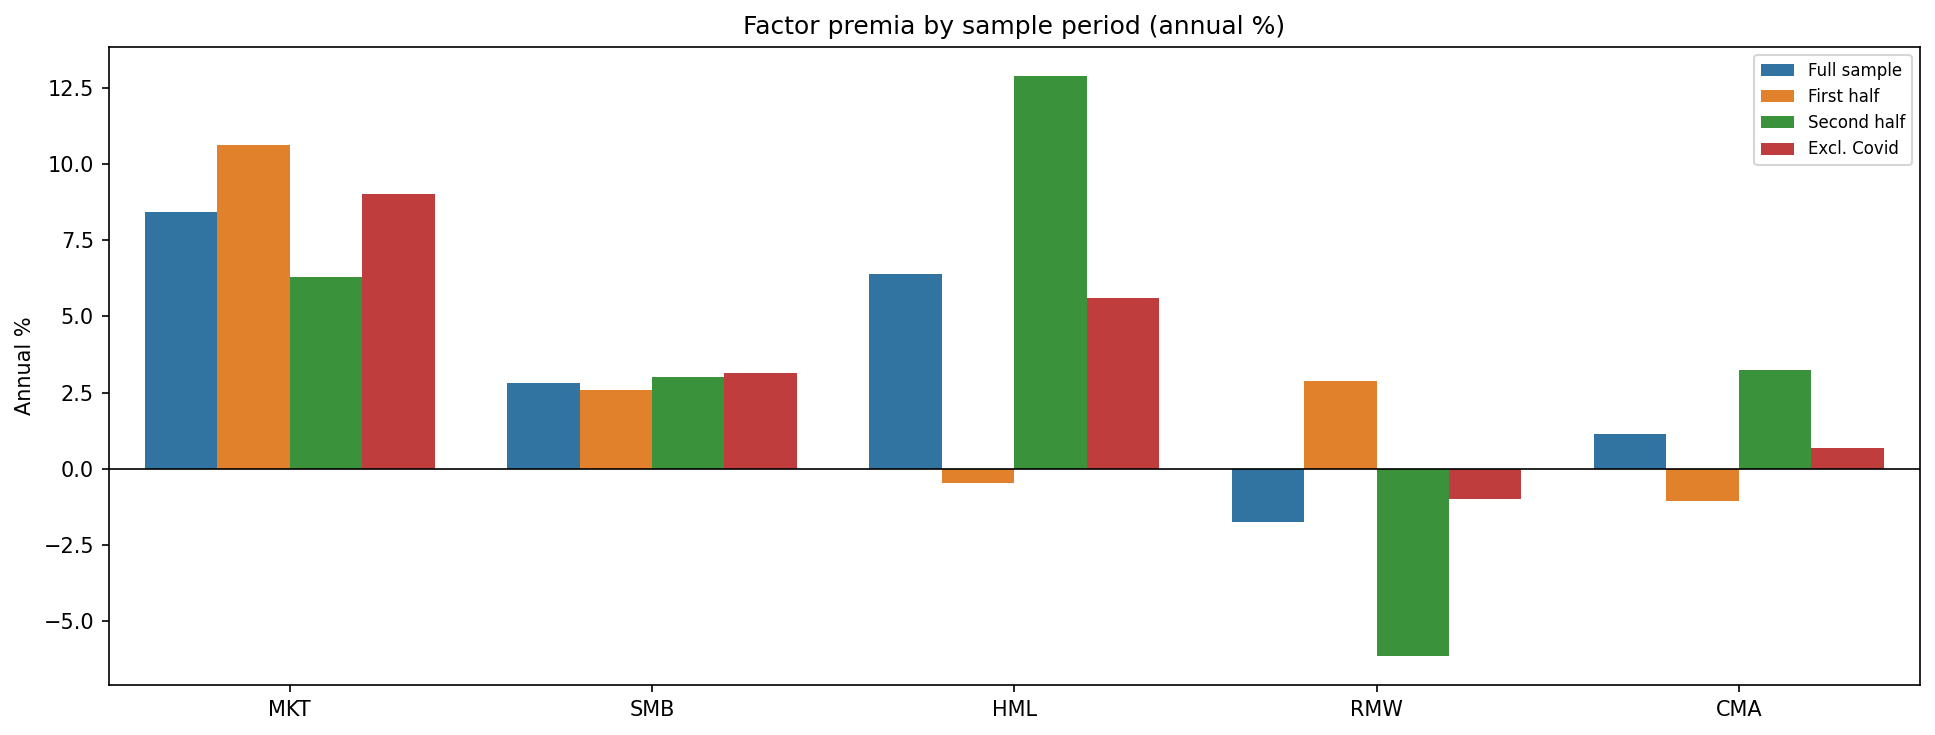

In [29]:
# 4.3 Plot - annual premium of each factor in each period

fig, ax = plt.subplots(figsize=(13, 5), dpi=150)
sns.barplot(data=period_premia, x="factor", y="mean_annual_%", hue="period",
            order=FACTOR_COLS, hue_order=list(PERIODS), ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Factor premia by sample period (annual %)")
ax.set_xlabel("")
ax.set_ylabel("Annual %")
ax.legend(title="", fontsize=8)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4_3_premia_by_period.png", bbox_inches="tight", dpi=300)
plt.show()

In [30]:
# 4.4 Save

period_premia.to_csv(OUTPUT_DIR / "phase_4_period_premia.csv", index=False)
period_models.to_csv(OUTPUT_DIR / "phase_4_period_models.csv", index=False)
period_spanning.to_csv(OUTPUT_DIR / "phase_4_period_spanning.csv", index=False)
period_mid.to_csv(OUTPUT_DIR / "phase_4_period_mid_row.csv", index=False)
print("Saved: period premia, model tests, spanning, Mid-row intercepts")

Saved: period premia, model tests, spanning, Mid-row intercepts


## Inferences: Time stability

*First half: Jul-2016 to Jun-2021 (60 months); second half: Jul-2021 to Sep-2026 (63 months); "Excl. Covid" drops Mar–Jun 2020 (119 months).*

**1. The value premium comes entirely from the second half.**

| Factor, annual % (NW t) | First half | Second half | Excl. Covid |
|---|---|---|---|
| MKT | 10.6 (1.37) | 6.3 (1.06) | 9.0 (1.99) |
| SMB | 2.6 (0.43) | 3.0 (0.75) | 3.1 (0.85) |
| **HML** | **−0.5 (−0.08)** | **12.9 (3.02)** | 5.6 (1.37) |
| RMW | 2.9 (1.12) | −6.2 (−1.83) | −1.0 (−0.37) |
| CMA | −1.0 (−0.35) | 3.2 (0.83) | 0.7 (0.26) |

- **HML earned nothing in 2016–21 and 12.9% a year in 2021–26** (t = 3.0, the only Fragile premium verdict): the PSU, energy and metals re-rating.
- **RMW flips sign** (+2.9% → −6.2%): the same regime from the other side. Quality lagged when cyclicals and PSUs rallied. Neither half is significant.
- **SMB is the most stable premium** (2.6% and 3.0% a year), but small and insignificant in both halves.

**2. The B/M rejection depends on the full sample and the Covid months.**

| FF5 GRS p-value | Full | First half | Second half | Excl. Covid |
|---|---|---|---|---|
| B/M | **0.037** | 0.133 | 0.189 | 0.109 |
| OP | 0.095 | **0.013** | 0.748 | 0.116 |
| INV | 0.460 | 0.359 | **0.048** | 0.723 |
| All 27 | 0.128 | 0.365 | 0.702 | 0.271 |

- FF5 is rejected on B/M in the full sample only; dropping the four Covid months alone removes the rejection.
- **The rejected sort changes with the period** (OP in the first half, INV in the second). There is no stable failure, which fits noise in 60-month samples more than a persistent mispricing.
- 15 of the 48 sub-period GRS verdicts are Fragile, 12 of them on the B/M sort, consistent with the borderline full-sample p-value.

**3. HML is redundant only in the first half.** Spanning t: −0.66 (first half), **2.08 (second half)**, 1.24 (excl. Covid). In 2021–26, value carried information that RMW and CMA did not.

**4. The mid-cap intercept is the most persistent result:** +0.21% (first half), +0.22% (second half), +0.15% (excl. Covid), always positive, with 2–3 of 9 significant.

**5. FF5 vs FF3:** A|a| is equal or worse for FF5 in every period (first half 0.23 vs 0.21, second half 0.23 vs 0.23, excl. Covid 0.12 vs 0.12). Pricing errors are larger within each half (0.21–0.32%) because 60 months give noisier intercepts.

## Step 5: Industry portfolios (test assets the model was not built on)

The 27 test portfolios are sorted on the same characteristics as the factors, which makes them an easy target. Industry portfolios are not, so they are a stricter out-of-sample test (Fama & French 1997; Lewellen, Nagel & Shanken 2010).

- **Labels:** each stock's broad sector from Phase 1 (Screener, NSE classification). Delisted stocks have labels too, so there is no survivorship bias.
- **Grouping rule (fixed in advance, stock counts only):** a sector with fewer than 10 stocks in any June joins "Other", as do stocks without a label. "Other" is used as a test asset only if it also has at least 10 stocks every June.
- **Portfolios:** all universe stocks of each industry, value-weighted with last month's ME; excess return over Rf.

In [31]:
# 5.1 Industry labels and grouping (decided from stock counts only, never from returns)

pan = panel_df[panel_df["date"].isin(df_factors.index)].copy()
pan["sector"] = pan["broad_sector"].fillna("Unclassified")

# Stocks per sector in each holding year
counts = pan.groupby(["sector", "formation_date"])["symbol"].nunique().unstack(fill_value=0)
counts.columns = counts.columns.year
too_small = counts.index[(counts.min(axis=1) < MIN_INDUSTRY_STOCKS) | (counts.index == "Unclassified")]
pan["industry"] = np.where(pan["sector"].isin(too_small), "Other", pan["sector"])

# "Other" is a test asset only if it is itself large enough every June; otherwise it is left out
other_counts = pan[pan["industry"] == "Other"].groupby("formation_date")["symbol"].nunique()
if len(other_counts) and (len(other_counts) < pan["formation_date"].nunique() or other_counts.min() < MIN_INDUSTRY_STOCKS):
    print(f"'Other' has as few as {other_counts.min()} stocks in a June: left out of the test assets")
    pan = pan[pan["industry"] != "Other"]

print("Sectors joined into 'Other':", list(too_small))
display(pan.groupby(["industry", "formation_date"])["symbol"].nunique().unstack(fill_value=0)
        .rename(columns=lambda d: d.year))

Sectors joined into 'Other': ['Diversified', 'Telecommunication', 'Unclassified']


formation_date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
industry,,,,,,,,,,,
Commodities,52,58,62,59,62,66,69,65,59,55,56
Consumer Discretionary,116,114,114,112,108,103,120,111,104,99,104
Energy,17,18,17,18,18,17,16,16,17,17,18
Fast Moving Consumer Goods,35,33,35,33,34,32,32,32,29,30,29
Financial Services,61,66,78,81,79,84,82,88,90,92,101
Healthcare,40,40,35,39,45,47,40,40,44,50,49
Industrials,67,63,63,66,72,64,60,73,82,82,80
Information Technology,19,17,17,18,19,24,25,24,27,26,23
Other,52,51,45,39,28,30,25,20,18,16,10


In [32]:
# 5.2 Monthly value-weighted industry returns (weights = last month's ME)

ind = pan[pan["me_lag"] > 0].copy()
ind["w_ret"] = ind["me_lag"] * ind["ret"]
g = ind.groupby(["date", "industry"]).agg(w_ret=("w_ret", "sum"), w=("me_lag", "sum"), n=("symbol", "count"))

industry_excess = (g["w_ret"] / g["w"]).unstack("industry").sub(df_factors["Rf"], axis=0).loc[df_factors.index]
industry_n = g["n"].unstack("industry")

print("Industries:", industry_excess.shape[1], "| months:", len(industry_excess))
print("Missing industry-months:", int(industry_excess.isna().sum().sum()),
      "| fewest stocks in any industry-month:", int(industry_n.min().min()))
assert industry_excess.notna().all().all(), "An industry has a missing month: raise MIN_INDUSTRY_STOCKS"

display(pd.DataFrame({
    "avg_stocks": industry_n.mean(),
    "min_stocks": industry_n.min(),
    "mean_excess_monthly_%": industry_excess.mean() * 100,
    "std_monthly_%": industry_excess.std() * 100,
}).round(2))

Industries: 11 | months: 123
Missing industry-months: 0 | fewest stocks in any industry-month: 9


,avg_stocks,min_stocks,mean_excess_monthly_%,std_monthly_%
industry,,,,
Commodities,60.50,51,1.11,6.32
Consumer Discretionary,109.95,99,0.69,5.61
Energy,17.12,16,0.80,6.32
Fast Moving Consumer Goods,32.33,29,0.31,4.33
Financial Services,80.56,61,0.73,6.51
Healthcare,42.16,35,0.62,5.31
Industrials,69.46,60,1.18,6.77
Information Technology,21.63,17,0.53,6.20
Other,29.93,9,0.72,5.50


In [33]:
# 5.3 Model tests on the industry portfolios

IND_SETS = {"IND": list(industry_excess.columns)}
ind_models, ind_ports = evaluate_models(industry_excess, df_factors[FACTOR_COLS], MODELS, IND_SETS)
display(ind_models.round(3))

# FF5 intercept and loadings of each industry
rows = []
X = sm.add_constant(df_factors[FACTOR_COLS])
for name in industry_excess.columns:
    fit = sm.OLS(industry_excess[name], X).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    rows.append({"industry": name, "a_monthly_%": fit.params["const"] * 100, "t_a_nw": fit.tvalues["const"],
                 **{f"b_{f}": fit.params[f] for f in FACTOR_COLS}, "r_squared": fit.rsquared})
industry_ff5 = pd.DataFrame(rows).set_index("industry").sort_values("a_monthly_%")
display(industry_ff5.round(2))

,model,sort_type,n_portfolios,GRS,p_value,n_significant_a,avg_abs_a,abs_a_to_abs_r,share_unexplained,sampling_error_share,avg_R2,avg_adj_R2
0,CAPM,IND,11,0.962,0.485,0,0.174,0.724,0.603,2.321,0.631,0.628
1,FF3,IND,11,0.879,0.563,0,0.174,0.727,0.568,2.211,0.677,0.669
2,FF4_noHML,IND,11,0.948,0.498,0,0.160,0.669,0.599,1.855,0.698,0.688
3,FF5,IND,11,0.945,0.501,0,0.183,0.765,0.795,1.320,0.714,0.701


,a_monthly_%,t_a_nw,b_MKT,b_SMB,b_HML,b_RMW,b_CMA,r_squared
industry,,,,,,,,
Financial Services,-0.19,-0.77,1.06,0.09,0.37,0.07,-0.32,0.85
Energy,-0.04,-0.16,0.94,-0.59,0.59,-0.21,-0.28,0.76
Other,-0.03,-0.16,0.90,-0.03,0.25,0.00,-0.05,0.76
Fast Moving Consumer Goods,-0.02,-0.09,0.84,-0.10,-0.46,0.13,0.31,0.66
Consumer Discretionary,0.04,0.28,1.01,0.27,-0.21,-0.03,-0.19,0.88
Information Technology,0.07,0.21,1.06,-0.25,-0.31,1.03,0.93,0.56
Healthcare,0.16,0.40,0.74,0.07,-0.20,-0.07,0.21,0.42
Services,0.18,0.68,1.09,0.29,-0.20,-0.46,-0.22,0.76
Commodities,0.25,1.03,1.06,0.11,0.19,0.11,-0.06,0.78


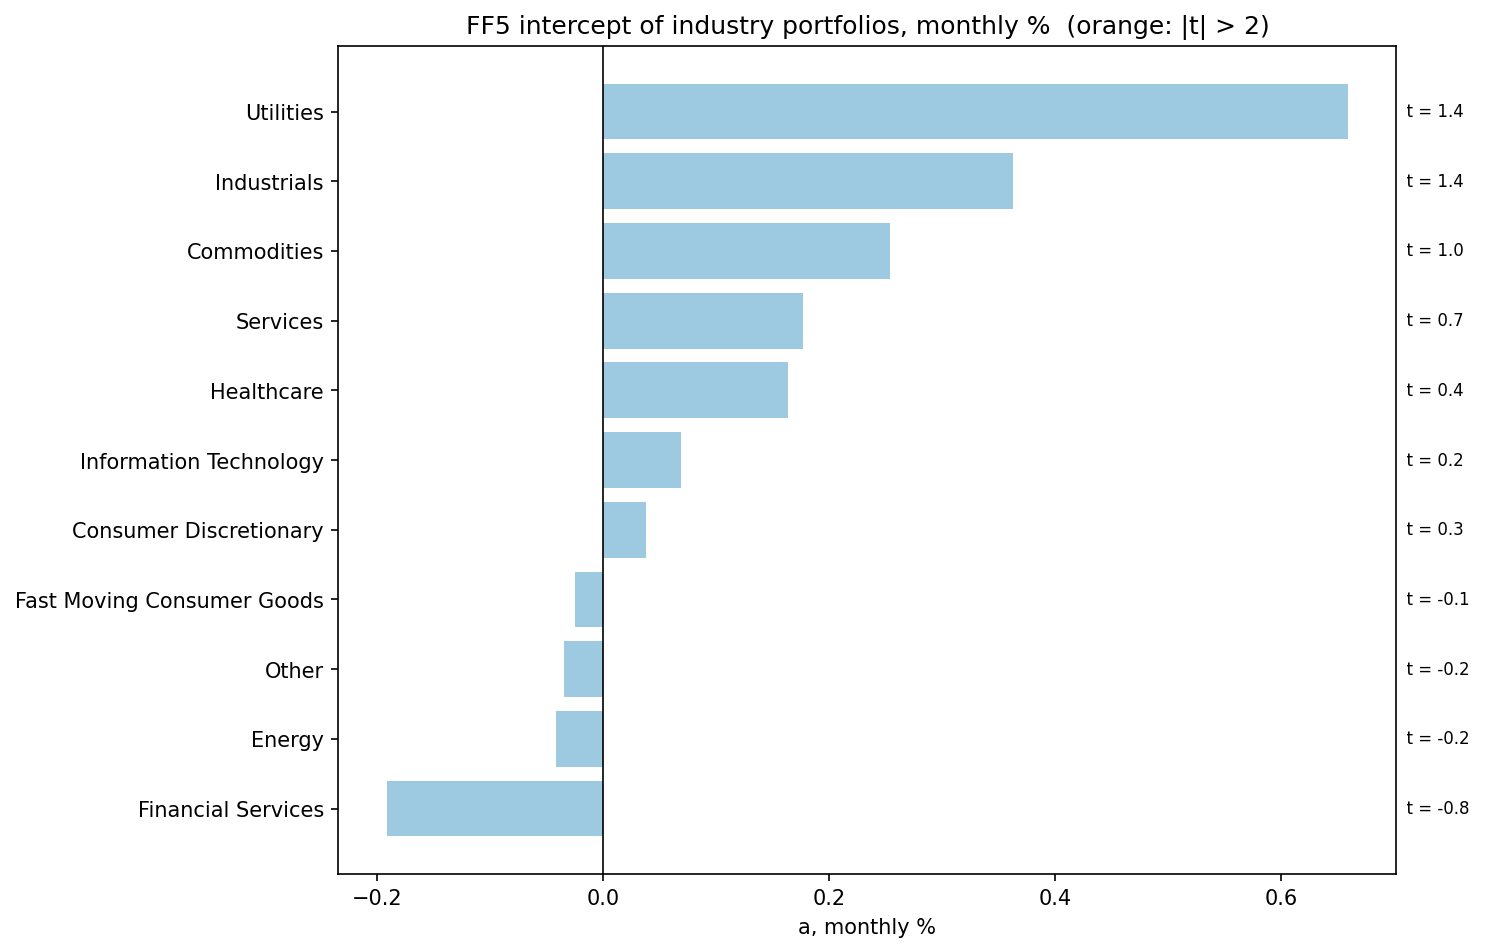

In [34]:
# 5.4 Plot - FF5 intercept of each industry (Newey-West t on the right)

fig, ax = plt.subplots(figsize=(10, 0.45 * len(industry_ff5) + 1.5), dpi=150)
colors = np.where(industry_ff5["t_a_nw"].abs() > T_CRIT, "#e76f51", "#9ecae1")
ax.barh(industry_ff5.index, industry_ff5["a_monthly_%"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
for i, (a, t) in enumerate(zip(industry_ff5["a_monthly_%"], industry_ff5["t_a_nw"])):
    ax.text(ax.get_xlim()[1], i, f"  t = {t:.1f}", va="center", fontsize=8)
ax.set_title("FF5 intercept of industry portfolios, monthly %  (orange: |t| > 2)")
ax.set_xlabel("a, monthly %")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "5_4_industry_intercepts.png", bbox_inches="tight", dpi=300)
plt.show()

In [35]:
# 5.5 Save

industry_excess.to_csv(OUTPUT_DIR / "phase_4_industry_returns.csv")
ind_models.to_csv(OUTPUT_DIR / "phase_4_industry_models.csv", index=False)
industry_ff5.to_csv(OUTPUT_DIR / "phase_4_industry_ff5.csv")
print("Saved: industry excess returns, model tests, FF5 intercepts and loadings")

Saved: industry excess returns, model tests, FF5 intercepts and loadings


## Inferences: Industry portfolios

*11 industries (NSE broad sectors; Diversified, Telecommunication and unlabelled stocks joined into "Other"). Every industry has at least 10 stocks each June (at least 9 in any month).*

**1. No model is rejected on industries, and no industry has a significant intercept.**

| Model | GRS (p) | A\|a\|, % | A(a²)/A(r̄²) | Avg R² |
|---|---|---|---|---|
| CAPM | 0.96 (0.49) | 0.17 | 0.60 | 0.63 |
| FF3 | 0.88 (0.56) | 0.17 | 0.57 | 0.68 |
| FF4 (no HML) | 0.95 (0.50) | 0.16 | 0.60 | 0.70 |
| FF5 | 0.95 (0.50) | 0.18 | 0.80 | 0.71 |

- FF5 passes the out-of-sample test, but so does CAPM: industry average returns (0.3–1.3% a month) are too close to each other, given their volatility (4–9% a month), to separate the models. The sampling-error share is above 1 for every model (1.3–2.3), so the intercepts are no more dispersed than noise.
- R² is much lower than for the characteristic portfolios (0.71 vs 0.93 for FF5). Industries carry risk the five factors do not span; Healthcare (R² = 0.42) is the most idiosyncratic.

**2. The loadings make economic sense, which supports the factors' construction.**
- **IT:** most profitable and most conservative (RMW +1.03, CMA +0.93), growth tilt (HML −0.31).
- **Utilities:** weakest profitability (RMW −1.53); highest intercept (+0.66%, t = 1.36), from the 2022–24 power-sector rally.
- **Energy and Financials:** value (HML +0.59 and +0.37); Energy is large-cap (SMB −0.59).
- **FMCG:** defensive (MKT beta 0.84) and growth (HML −0.46).
- **Industrials:** small/mid-cap and capex-heavy (SMB +0.52, RMW −0.47); intercept +0.36% (t = 1.39), from the capex cycle.

**Conclusion:** FF5 is not rejected on assets it was not built on, but this test has little power to tell models apart.

## Step 6: Statistical robustness

The GRS F-test assumes normally distributed residuals. Indian monthly returns have fat tails (Covid crash, small-cap swings), so:
1. **Normality:** Jarque-Bera test on each portfolio's FF5 residuals.
2. **Bootstrap GRS p-values:** the model is imposed (all intercepts set to zero) and months are resampled with replacement, keeping each month's factors and residuals together, so fat tails and cross-correlations are kept. The p-value is the share of bootstrap GRS values at least as large as the observed one (2,000 repetitions, fixed seed).

**Verdict:** Pass if the bootstrap p-value gives the same 5% decision as the F-test.

In [36]:
# 6.1 Jarque-Bera test on FF5 residuals (test portfolios and industries)

all_excess = excess_wide.join(industry_excess)
_, resid_ff5 = time_series_stats(all_excess, df_factors.loc[all_excess.index, MODELS["FF5"]])

normality = pd.DataFrame({
    "group": np.where(resid_ff5.columns.isin(excess_wide.columns), "test portfolios", "industries"),
    "skew": resid_ff5.skew(),
    "excess_kurtosis": resid_ff5.kurt(),
    "jb_p_value": [stats.jarque_bera(resid_ff5[c])[1] for c in resid_ff5.columns],
}, index=resid_ff5.columns)
normality["normal_rejected_5%"] = normality["jb_p_value"] < ALPHA

print(normality.groupby("group")["normal_rejected_5%"].agg(rejected="sum", portfolios="count"))
display(normality.round(3))

                 rejected  portfolios
group                                
industries              4          11
test portfolios         6          27


,group,skew,excess_kurtosis,jb_p_value,normal_rejected_5%
BM_S1_C1,test portfolios,0.507,0.465,0.051,False
BM_S1_C2,test portfolios,-0.075,0.290,0.826,False
BM_S1_C3,test portfolios,-0.093,-0.113,0.860,False
BM_S2_C1,test portfolios,-0.129,0.657,0.355,False
BM_S2_C2,test portfolios,0.052,0.578,0.504,False
BM_S2_C3,test portfolios,-0.047,0.422,0.706,False
BM_S3_C1,test portfolios,-0.231,0.731,0.197,False
BM_S3_C2,test portfolios,0.220,0.726,0.210,False
BM_S3_C3,test portfolios,1.531,7.038,0.000,True
INV_S1_C1,test portfolios,0.159,-0.312,0.569,False


In [37]:
# 6.2 Bootstrap GRS p-values (intercepts set to zero)

def grs_from_arrays(R, F):
    """GRS statistic from return (T x N) and factor (T x L) arrays."""
    T, N, L = R.shape[0], R.shape[1], F.shape[1]
    X = np.column_stack([np.ones(T), F])
    B = np.linalg.lstsq(X, R, rcond=None)[0]
    E = R - X @ B
    sigma = E.T @ E / T
    mu = F.mean(axis=0)
    omega = (F - mu).T @ (F - mu) / T
    a = B[0]
    return (T - N - L) / N * (a @ np.linalg.solve(sigma, a)) / (1 + mu @ np.linalg.solve(omega, mu))


def bootstrap_grs(excess, factors, n_boot=N_BOOT, seed=SEED):
    """Observed GRS, its bootstrap p-value under zero intercepts, and the bootstrap draws."""
    R, F = excess.values, factors.values
    T = len(F)
    X = np.column_stack([np.ones(T), F])
    B = np.linalg.lstsq(X, R, rcond=None)[0]
    E = R - X @ B                         # residuals
    R_null = F @ B[1:]                    # returns the factors explain, with no intercept

    rng = np.random.default_rng(seed)
    draws = np.empty(n_boot)
    for i in range(n_boot):
        t = rng.integers(0, T, T)         # resample months: factors and residuals stay together
        draws[i] = grs_from_arrays(R_null[t] + E[t], F[t])

    grs = grs_from_arrays(R, F)
    return grs, (draws >= grs).mean(), draws


BOOT_SETS = {name: (excess_wide, ids) for name, ids in TEST_SETS.items()}
BOOT_SETS["IND"] = (industry_excess, list(industry_excess.columns))

rows, boot_draws = [], {}
for model_name, cols in MODELS.items():
    for set_name, (excess, ids) in BOOT_SETS.items():
        f = df_factors.loc[excess.index, cols]
        grs, p_boot, draws = bootstrap_grs(excess[ids], f)
        p_f = stats.f.sf(grs, len(ids), len(f) - len(ids) - len(cols))
        rows.append({"model": model_name, "sort_type": set_name, "GRS": grs,
                     "p_value_F": p_f, "p_value_boot": p_boot, "verdict": grs_verdict(p_f, p_boot)})
        boot_draws[(model_name, set_name)] = draws
bootstrap_table = pd.DataFrame(rows)

# The observed GRS must equal the Step 1 baseline
check = bootstrap_table.merge(baseline_models[["model", "sort_type", "GRS"]], on=["model", "sort_type"])
print("GRS vs baseline, largest difference:", f"{(check['GRS_x'] - check['GRS_y']).abs().max():.1e}")

display(bootstrap_table.round(3))

GRS vs baseline, largest difference: 1.9e-14


,model,sort_type,GRS,p_value_F,p_value_boot,verdict
0,CAPM,BM,1.985,0.047,0.058,Fragile
1,CAPM,OP,1.070,0.390,0.398,Pass
2,CAPM,INV,0.490,0.879,0.882,Pass
3,CAPM,ALL,1.416,0.112,0.182,Pass
4,CAPM,IND,0.962,0.485,0.483,Pass
5,FF3,BM,2.136,0.032,0.040,Pass
6,FF3,OP,1.408,0.193,0.210,Pass
7,FF3,INV,0.646,0.755,0.755,Pass
8,FF3,ALL,1.357,0.143,0.238,Pass
9,FF3,IND,0.879,0.563,0.560,Pass


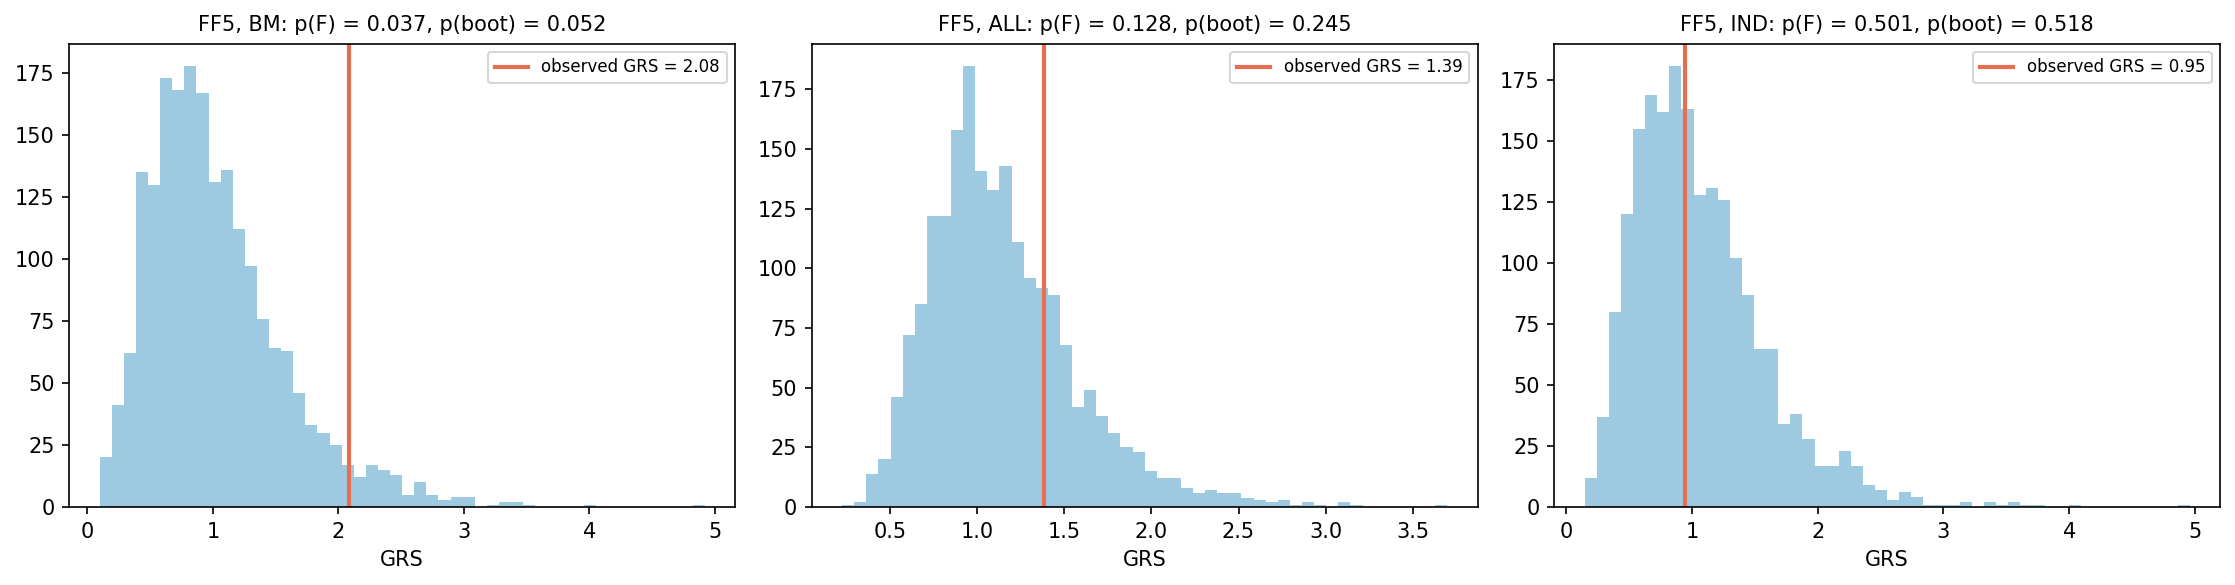

In [38]:
# 6.3 Plot - bootstrap distribution of GRS under zero intercepts (FF5)

plot_sets = [s for s in ["BM", "ALL", "IND"] if ("FF5", s) in boot_draws]
fig, axes = plt.subplots(1, len(plot_sets), figsize=(5 * len(plot_sets), 4), dpi=150)
for ax, set_name in zip(np.atleast_1d(axes), plot_sets):
    row = bootstrap_table[(bootstrap_table["model"] == "FF5") & (bootstrap_table["sort_type"] == set_name)].iloc[0]
    ax.hist(boot_draws[("FF5", set_name)], bins=50, color="#9ecae1")
    ax.axvline(row["GRS"], color="#e76f51", linewidth=2, label=f"observed GRS = {row['GRS']:.2f}")
    ax.set_title(f"FF5, {set_name}: p(F) = {row['p_value_F']:.3f}, p(boot) = {row['p_value_boot']:.3f}", fontsize=10)
    ax.set_xlabel("GRS")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "6_3_bootstrap_grs.png", bbox_inches="tight", dpi=300)
plt.show()

In [39]:
# 6.4 Save

normality.to_csv(OUTPUT_DIR / "phase_4_residual_normality.csv")
bootstrap_table.to_csv(OUTPUT_DIR / "phase_4_bootstrap_grs.csv", index=False)
print("Saved: residual normality, bootstrap GRS")

Saved: residual normality, bootstrap GRS


## Inferences: Statistical robustness

**1. Fat tails in a minority of portfolios.**
Normality is rejected for 6 of 27 test portfolios and 4 of 11 industries (Jarque-Bera, 5%). Worst cases:
- **BM_S3_C3** (big value: skew 1.53, excess kurtosis 7.0), driven by the PSU-bank and energy rally months;
- **OP_S1_C3** and **OP_S3_C1** (kurtosis 2.7 and 2.4);
- among industries: Financials, Healthcare, Industrials and IT.

**2. Bootstrap GRS: 18 of 20 verdicts match the F-test.**

| Model, set | p (F-test) | p (bootstrap) | Verdict |
|---|---|---|---|
| CAPM, B/M | 0.047 | 0.058 | Fragile |
| FF3, B/M | 0.032 | 0.040 | Pass |
| FF4 (no HML), B/M | 0.024 | 0.036 | Pass |
| **FF5, B/M** | **0.037** | **0.052** | **Fragile** |
| FF5, all 27 | 0.128 | 0.245 | Pass |
| FF5, industries | 0.501 | 0.518 | Pass |

- The bootstrap p-values are a little higher than the F-test's. With fat tails, the F-test slightly over-rejects.
- **FF5's B/M rejection is not robust:** p = 0.052 by bootstrap, significant at 10% but not 5%. FF3 and FF4 are still rejected at 5% on B/M.
- On all 27 portfolios the bootstrap makes rejection even less likely (FF5 p = 0.25).

## Step 7: Momentum (UMD), Carhart and FF-6

FF-5 has no momentum factor; FF (2015) list momentum as a known gap. Here:
1. **UMD is built from our own data** (Carhart 1997, Ken French's construction). Each month t, universe stocks are sorted 2×3 on size (median ME at the end of t−1) and prior return over months t−12 to t−2 (30/70 breakpoints from Big stocks). UMD = ½(Small Up + Big Up) − ½(Small Down + Big Down), value-weighted, rebalanced monthly. A stock needs all 11 prior monthly returns.
2. **Validated** against IIMA's momentum factor (WML).
3. **Spanning:** is UMD explained by the FF-5 factors?
4. **Model comparison:** Carhart (MKT, SMB, HML, UMD) and FF-6 (FF-5 + UMD) against FF3 and FF-5, on the test portfolios and the industries.

FF-5 remains the main model; Carhart and FF-6 are comparisons only.

In [40]:
# 7.1 Prior return (months t-12 to t-2) for every stock, from the full Phase 1 history

hist = pd.read_csv(FILES["phase1_panel"], usecols=["symbol", "date", "ret", "me_lag", "in_universe"],
                   parse_dates=["date"])
hist["in_universe"] = hist["in_universe"].astype(bool)
hist = hist.sort_values(["symbol", "date"]).reset_index(drop=True)

# Phase 1 gives each stock a full month grid (no-trade months have ret = NaN), so shifting rows = shifting months
gaps = hist.groupby("symbol")["date"].diff().dt.days.dropna()
assert gaps.between(28, 31).all(), "Phase 1 month grid has gaps: prior returns would be wrong"

log_ret = np.log1p(hist["ret"])
hist["prior_ret"] = np.expm1(
    log_ret.groupby(hist["symbol"]).transform(lambda s: s.shift(2).rolling(11, min_periods=11).sum()))

mom = hist[hist["in_universe"] & hist["ret"].notna() & (hist["me_lag"] > 0) & hist["prior_ret"].notna()]
mom = mom[mom["date"].isin(df_factors.index)].copy()
per_month = mom.groupby("date").size()
print("Stock-months:", len(mom), "| stocks per month: min", per_month.min(), "| median", int(per_month.median()))

Stock-months: 60379 | stocks per month: min 471 | median 492


In [41]:
# 7.2 UMD: monthly 2x3 sort on size and prior return, value-weighted

mom["SIZE"] = np.where(mom["me_lag"] <= mom.groupby("date")["me_lag"].transform("median"), "S", "B")
big = mom[mom["SIZE"] == "B"].groupby("date")["prior_ret"]
low = mom["date"].map(big.quantile(BP_LOW))
high = mom["date"].map(big.quantile(BP_HIGH))
mom["MOM"] = "N"
mom.loc[mom["prior_ret"] <= low, "MOM"] = "D"          # down: past losers
mom.loc[mom["prior_ret"] >= high, "MOM"] = "U"         # up: past winners
mom["PORT"] = mom["SIZE"] + mom["MOM"]

mom["w_ret"] = mom["me_lag"] * mom["ret"]
g = mom.groupby(["date", "PORT"]).agg(w_ret=("w_ret", "sum"), w=("me_lag", "sum"), n=("symbol", "count"))
mom_ports = (g["w_ret"] / g["w"]).where(g["n"] >= MIN_STOCKS).unstack("PORT")

umd = (mom_ports[["SU", "BU"]].mean(axis=1, skipna=False)
       - mom_ports[["SD", "BD"]].mean(axis=1, skipna=False)).rename("UMD").reindex(df_factors.index)
print("UMD months:", int(umd.notna().sum()), "of", len(df_factors), "| fewest stocks in a portfolio-month:", int(g["n"].min()))
assert umd.notna().all(), "UMD is missing in some months"

factors6 = df_factors[FACTOR_COLS].join(umd)

UMD months: 123 of 123 | fewest stocks in a portfolio-month: 15


In [42]:
# 7.3 UMD premium, check against IIMA's WML, and spanning by the FF-5 factors

both = pd.DataFrame({"UMD_ours": umd, "WML_iima": iima["WML"]}).dropna()
both_p = factor_premia(both)
umd_corr = both["UMD_ours"].corr(both["WML_iima"])

umd_check = pd.DataFrame({
    "value": [len(both), umd_corr,
              both_p.loc["UMD_ours", "mean_monthly_%"], both_p.loc["UMD_ours", "t_stat_nw"],
              both_p.loc["WML_iima", "mean_monthly_%"], both_p.loc["WML_iima", "t_stat_nw"]],
}, index=["overlap_months", "correlation_with_iima_wml", "ours_mean_%", "ours_t_nw", "iima_mean_%", "iima_t_nw"])
UMD_CORR_VERDICT = correlation_verdict(umd_corr)
UMD_PREMIUM_VERDICT = premium_verdict(both_p.loc["UMD_ours", "mean_monthly_%"], both_p.loc["UMD_ours", "t_stat_nw"],
                                      both_p.loc["WML_iima", "mean_monthly_%"], both_p.loc["WML_iima", "t_stat_nw"])
display(umd_check.round(3))
print("Correlation verdict:", UMD_CORR_VERDICT, "| premium verdict (same conclusion as IIMA?):", UMD_PREMIUM_VERDICT)

umd_premium = factor_premia(factors6[["UMD"]])
display(umd_premium.round(3))

# Is momentum explained by the FF-5 factors?
fit = sm.OLS(factors6["UMD"], sm.add_constant(factors6[FACTOR_COLS])).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
umd_spanning = pd.DataFrame({"coef": fit.params, "t_nw": fit.tvalues})
umd_spanning.loc["const", "coef"] *= 100                 # intercept in monthly %
umd_spanning = umd_spanning.rename(index={"const": "intercept_monthly_%"})
print(f"UMD on FF-5: R-squared = {fit.rsquared:.3f}")
display(umd_spanning.round(3))
print("Correlation of UMD with the FF-5 factors:")
display(factors6.corr().loc[FACTOR_COLS, ["UMD"]].round(2).T)

,value
overlap_months,114.000
correlation_with_iima_wml,0.725
ours_mean_%,0.882
ours_t_nw,2.660
iima_mean_%,1.133
iima_t_nw,3.307


Correlation verdict: Pass | premium verdict (same conclusion as IIMA?): Pass


,mean_annual_%,mean_monthly_%,n_months,t_stat,t_stat_nw
factor,,,,,
UMD,11.205,0.934,123.0,2.847,3.024


UMD on FF-5: R-squared = 0.054


,coef,t_nw
intercept_monthly_%,1.077,3.867
MKT,-0.048,-0.572
SMB,-0.040,-0.308
HML,-0.172,-1.137
RMW,0.033,0.173
CMA,-0.045,-0.208


Correlation of UMD with the FF-5 factors:


,MKT,SMB,HML,RMW,CMA
UMD,-0.14,-0.12,-0.22,0.16,-0.06


In [43]:
# 7.4 Carhart and FF-6 vs FF3 and FF-5, on the test portfolios and the industries

MODELS_MOM = {
    "FF3":     MODELS["FF3"],
    "Carhart": MODELS["FF3"] + ["UMD"],
    "FF5":     MODELS["FF5"],
    "FF6":     MODELS["FF5"] + ["UMD"],
}
tp_table, _ = evaluate_models(excess_wide, factors6.loc[excess_wide.index], MODELS_MOM, TEST_SETS)
ind_table, _ = evaluate_models(industry_excess, factors6.loc[industry_excess.index], MODELS_MOM, IND_SETS)
momentum_models = pd.concat([tp_table, ind_table], ignore_index=True)

for value in ["GRS", "p_value", "avg_abs_a", "abs_a_to_abs_r", "avg_R2"]:
    print(value)
    display(momentum_models.pivot(index="sort_type", columns="model", values=value)[list(MODELS_MOM)].round(3))

GRS


model,FF3,Carhart,FF5,FF6
sort_type,,,,
ALL,1.357,1.531,1.386,1.542
BM,2.136,2.832,2.082,2.762
IND,0.879,1.797,0.945,1.778
INV,0.646,0.801,0.981,1.209
OP,1.408,1.140,1.712,1.483


p_value


model,FF3,Carhart,FF5,FF6
sort_type,,,,
ALL,0.143,0.070,0.128,0.067
BM,0.032,0.005,0.037,0.006
IND,0.563,0.063,0.501,0.067
INV,0.755,0.616,0.460,0.297
OP,0.193,0.341,0.095,0.163


avg_abs_a


model,FF3,Carhart,FF5,FF6
sort_type,,,,
ALL,0.130,0.141,0.141,0.151
BM,0.145,0.182,0.146,0.181
IND,0.174,0.159,0.183,0.168
INV,0.092,0.108,0.108,0.132
OP,0.152,0.132,0.168,0.142


abs_a_to_abs_r


model,FF3,Carhart,FF5,FF6
sort_type,,,,
ALL,0.628,0.680,0.679,0.732
BM,0.507,0.636,0.510,0.632
IND,0.727,0.663,0.765,0.702
INV,0.613,0.721,0.719,0.877
OP,0.835,0.722,0.918,0.776


avg_R2


model,FF3,Carhart,FF5,FF6
sort_type,,,,
ALL,0.915,0.918,0.930,0.932
BM,0.927,0.929,0.929,0.932
IND,0.677,0.685,0.714,0.721
INV,0.922,0.923,0.942,0.944
OP,0.898,0.901,0.918,0.921


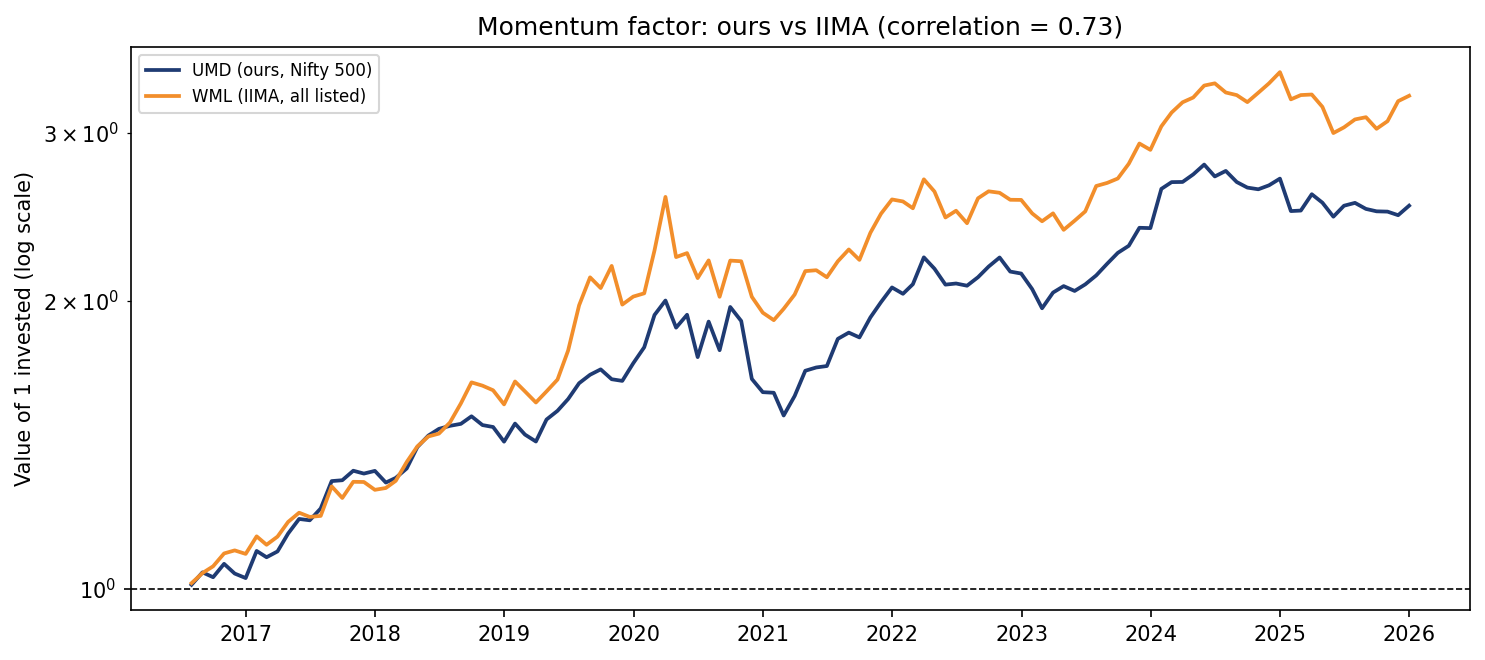

In [44]:
# 7.5 Plot - growth of 1: our UMD vs IIMA WML

fig, ax = plt.subplots(figsize=(10, 4.5), dpi=150)
ax.plot((1 + both["UMD_ours"]).cumprod(), color="#1f3b73", linewidth=1.8, label="UMD (ours, Nifty 500)")
ax.plot((1 + both["WML_iima"]).cumprod(), color="#f28e2b", linewidth=1.8, label="WML (IIMA, all listed)")
ax.set_yscale("log")
ax.axhline(1, color="black", linewidth=0.8, linestyle="--")
ax.set_title(f"Momentum factor: ours vs IIMA (correlation = {umd_corr:.2f})")
ax.set_ylabel("Value of 1 invested (log scale)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "7_5_umd_vs_iima.png", bbox_inches="tight", dpi=300)
plt.show()

In [45]:
# 7.6 Save (UMD is reused in Phase 5 as an extra exposure to report)

factors6.join(df_factors["Rf"]).to_csv(OUTPUT_DIR / "phase_4_factors_with_umd.csv")
umd_check.to_csv(OUTPUT_DIR / "phase_4_umd_check.csv")
umd_spanning.to_csv(OUTPUT_DIR / "phase_4_umd_spanning.csv")
momentum_models.to_csv(OUTPUT_DIR / "phase_4_momentum_models.csv", index=False)
print("Saved: factors with UMD, UMD check, UMD spanning, Carhart/FF6 model tests")

Saved: factors with UMD, UMD check, UMD spanning, Carhart/FF6 model tests


## Inferences: Momentum

**1. Momentum is the strongest premium in the Indian data.**
UMD earns **0.93% a month (11.2% a year), NW t = 3.02**, the only factor in this project above |t| = 2, and just above Harvey-Liu-Zhu's t = 3 hurdle for new factors.

**2. Validated against IIMA:** correlation 0.73 (Pass). On the 114 overlapping months, ours 0.88% (t = 2.66) vs IIMA's WML 1.13% (t = 3.31): the same conclusion, a little weaker in the Nifty 500 than across all listed stocks.

**3. FF5 does not explain momentum.**
UMD on the five factors: R² = 0.05 and intercept **1.08% a month (t = 3.87)**. Correlations with the FF5 factors are small (−0.22 to +0.16).

**4. Yet adding UMD makes the test portfolios harder to price, not easier.**

| GRS (p) | FF3 | Carhart | FF5 | FF6 |
|---|---|---|---|---|
| B/M | 2.14 (0.032) | 2.83 (0.005) | 2.08 (0.037) | 2.76 (0.006) |
| OP | 1.41 (0.193) | 1.14 (0.341) | 1.71 (0.095) | 1.48 (0.163) |
| INV | 0.65 (0.755) | 0.80 (0.616) | 0.98 (0.460) | 1.21 (0.297) |
| All 27 | 1.36 (0.143) | 1.53 (0.070) | 1.39 (0.128) | 1.54 (0.067) |
| Industries | 0.88 (0.563) | 1.80 (0.063) | 0.95 (0.501) | 1.78 (0.067) |

- A|a| on all 27 rises from 0.141% (FF5) to 0.151% (FF6); R² rises only from 0.930 to 0.932.
- **Why:** UMD has a large premium, but portfolios sorted on size, B/M, OP and investment hold a mix of winners and losers. Their small UMD loadings, multiplied by a 0.93% premium, move predicted returns away from actual returns, and the GRS test also counts UMD's own Sharpe ratio against the model.
- **Exception: the profitability sort.** Adding UMD improves it (Carhart GRS 1.14 vs FF3 1.41; A|a| 0.13% vs 0.15%), because past winners tend to be profitable firms.

**Conclusion:** FF5 stays the main model. Momentum is a large, separate premium that FF5 misses; Phase 5 should report each fund's or stock's UMD loading next to the FF5 loadings, and show alpha both with and without UMD.

## Step 8: Portfolio robustness

The main Phase 3 portfolio (FF5 score, equal weight, net of 0.25% costs) is rebuilt from the saved Phase 3 scores, and must match Phase 3 exactly. Then **one rule is changed at a time**:

| Variant | What changes |
|---|---|
| Cost 0.15% / 0.50% | One-way cost instead of 0.25% |
| Inverse vol | Inverse-volatility weights instead of equal weights |
| No caps | No 5% stock cap and no 25% sector cap |
| Top 10% / Top 30% | Hold the top 10% or 30% by score instead of 20% |
| With momentum | FF-5 + momentum score (Phase 3 variant) |

The main portfolio is also measured in the Step 4 periods (two halves, excluding Covid).

The **FF5 + momentum** variant is checked separately (8.3b) at 0.50% costs and in each period, because its 247% annual turnover makes it the most cost-sensitive version.

**Reported:** net CAGR, Sharpe, maximum drawdown, turnover; active return vs the Nifty 500 TRI and vs the equal-weighted universe; FF5 alpha and **FF6 alpha** (with UMD from Step 7), all with Newey-West t-stats.

**Verdicts (rules from Step 1):** the FF5 alpha and the active return vs the Nifty 500 TRI of each variant and period are compared with the main portfolio, using the factor-premium rule.

In [46]:
# 8.1 Load the Phase 3 portfolio files, and rebuild the Phase 3 portfolios exactly

scores = pd.read_csv(FILES["portfolio_scores"], parse_dates=["date"])
port_p3 = pd.read_csv(FILES["portfolio_returns"], parse_dates=["date"])
benchmarks = pd.read_csv(FILES["benchmarks"], parse_dates=["date"], index_col="date")


# Identical copy of the Phase 3 Step 7.2 builder
def cap_weights(w, sector, stock_cap, sector_cap, n_iter=100):
    """Cap single stocks and sectors; the excess goes to uncapped stocks in proportion. Weights sum to 1."""
    w = w / w.sum()
    for _ in range(n_iter):
        w = w.clip(upper=stock_cap)
        sector_total = w.groupby(sector).transform("sum")
        w = w * (sector_cap / sector_total).clip(upper=1)
        at_cap = (w >= stock_cap - 1e-12) | (w.groupby(sector).transform("sum") >= sector_cap - 1e-12)
        room = 1 - w.sum()
        if room < 1e-12 or at_cap.all():
            break
        w[~at_cap] += room * w[~at_cap] / w[~at_cap].sum()
    return w / w.sum()


def run_portfolio(scores, score_col, weighting="EW", top_share=0.20, stock_cap=0.05, sector_cap=0.25, cost=0.0025):
    """Monthly rebalanced long-only portfolio. Returns (monthly table, holdings).
    Turnover = half the sum of |new weight - drifted old weight|; cost = one-way cost x every rupee traded."""
    rows, holdings, prev = [], [], pd.Series(dtype=float)
    for date, g in scores[scores[score_col].notna()].groupby("date"):
        top = g.nlargest(int(np.ceil(top_share * len(g))), score_col).set_index("symbol")
        if weighting == "EW":
            w = pd.Series(1.0, index=top.index)
        else:                                                    # inverse volatility
            w = 1 / top["vol_12m"].fillna(top["vol_12m"].median())
        if stock_cap is not None or sector_cap is not None:
            w = cap_weights(w, top["sector"], stock_cap or 1.0, sector_cap or 1.0)
        w = w / w.sum()

        traded = w.subtract(prev, fill_value=0).abs().sum()
        held = top["ret"].notna()                                # no return = dropped this month
        gross = (w[held] * top.loc[held, "ret"]).sum() / w[held].sum()
        rows.append({"date": date, "gross_ret": gross, "cost": cost * traded, "net_ret": gross - cost * traded,
                     "turnover": traded / 2, "n_holdings": len(w)})
        holdings.append(pd.DataFrame({"date": date, "symbol": w.index, "weight": w.values,
                                      "score": top[score_col].values, "sector": top["sector"].values}))

        drifted = w[held] * (1 + top.loc[held, "ret"])           # weights at month-end after price moves
        prev = drifted / drifted.sum()
    return pd.DataFrame(rows).set_index("date"), pd.concat(holdings, ignore_index=True)


SPEC = PORTFOLIO_SPEC
for name, settings in PORTFOLIOS.items():
    res, _ = run_portfolio(scores, settings["score_col"], settings["weighting"], SPEC["top_share"],
                           SPEC["stock_cap"], SPEC["sector_cap"], SPEC["cost_one_way"])
    saved = port_p3[port_p3["portfolio"] == name].set_index("date")["net_ret"]
    gap = (res["net_ret"] - saved).abs().max()
    print(f"{name:36s} largest difference vs Phase 3: {gap:.1e}")
    assert res.index.equals(saved.index) and gap < 1e-10, f"{name}: rebuild differs from Phase 3"

FF5 score, equal weight              largest difference vs Phase 3: 9.7e-17
FF5 score, inverse vol               largest difference vs Phase 3: 9.7e-17
FF5 + momentum score, equal weight   largest difference vs Phase 3: 9.7e-17


In [47]:
# 8.2 Variants of the main portfolio (one change each), with verdicts against the main portfolio

def nw_mean(x):
    """Mean (monthly %) and Newey-West t-stat of a monthly series."""
    x = x.dropna()
    fit = sm.OLS(x, np.ones(len(x))).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    return x.mean() * 100, fit.tvalues.iloc[0]


def alpha(excess, cols):
    """Intercept (monthly %) and its Newey-West t-stat from a regression on the given factors."""
    fit = sm.OLS(excess, sm.add_constant(factors6.loc[excess.index, cols])).fit(
        cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    return fit.params["const"] * 100, fit.tvalues["const"]


def portfolio_stats(res, months):
    """Net performance, active returns and FF5 / FF6 alphas of one portfolio over the given months."""
    r = res["net_ret"].reindex(months).dropna()
    ex = r - df_factors["Rf"].reindex(r.index)
    wealth = (1 + r).cumprod()
    a5, t5 = alpha(ex, MODELS["FF5"])
    a6, t6 = alpha(ex, MODELS["FF5"] + ["UMD"])
    an, tn = nw_mean(r - benchmarks["Nifty 500 TRI"].reindex(r.index))
    ae, te = nw_mean(r - benchmarks["EW universe"].reindex(r.index))
    return {
        "months": len(r),
        "CAGR_net_%": (wealth.iloc[-1] ** (12 / len(r)) - 1) * 100,
        "sharpe": ex.mean() / ex.std() * np.sqrt(12),
        "max_drawdown_%": (wealth / wealth.cummax() - 1).min() * 100,
        "turnover_%_yr": res["turnover"].reindex(r.index).mean() * 1200,
        "active_vs_nifty500_monthly_%": an, "active_vs_nifty500_t_nw": tn,
        "active_vs_ew_universe_monthly_%": ae, "active_vs_ew_universe_t_nw": te,
        "ff5_alpha_monthly_%": a5, "ff5_alpha_t_nw": t5,
        "ff6_alpha_monthly_%": a6, "ff6_alpha_t_nw": t6,
    }


main_settings = dict(score_col=PORTFOLIOS[MAIN_PORTFOLIO]["score_col"], weighting=PORTFOLIOS[MAIN_PORTFOLIO]["weighting"],
                     top_share=SPEC["top_share"], stock_cap=SPEC["stock_cap"], sector_cap=SPEC["sector_cap"],
                     cost=SPEC["cost_one_way"])
VARIANTS = {
    "Main":          {},
    "Cost 0.15%":    {"cost": 0.0015},
    "Cost 0.50%":    {"cost": 0.0050},
    "Inverse vol":   {"weighting": "IV"},
    "No caps":       {"stock_cap": None, "sector_cap": None},
    "Top 10%":       {"top_share": 0.10},
    "Top 30%":       {"top_share": 0.30},
    "With momentum": {"score_col": "score_ff5_mom"},
}

variant_returns, rows = {}, []
for name, change in VARIANTS.items():
    res, _ = run_portfolio(scores, **{**main_settings, **change})
    variant_returns[name] = res
    rows.append({"variant": name, **portfolio_stats(res, df_factors.index)})
port_variants = pd.DataFrame(rows)


def add_verdicts(table, base):
    """FF5 alpha and active return vs the Nifty 500 TRI, each judged with the factor-premium rule."""
    table["verdict_ff5_alpha"] = [premium_verdict(base["ff5_alpha_monthly_%"], base["ff5_alpha_t_nw"], a, t)
                                  for a, t in zip(table["ff5_alpha_monthly_%"], table["ff5_alpha_t_nw"])]
    table["verdict_active"] = [premium_verdict(base["active_vs_nifty500_monthly_%"], base["active_vs_nifty500_t_nw"], a, t)
                               for a, t in zip(table["active_vs_nifty500_monthly_%"], table["active_vs_nifty500_t_nw"])]
    return table


port_variants = add_verdicts(port_variants, port_variants.set_index("variant").loc["Main"])
display(port_variants.set_index("variant").T.round(2))

variant,Main,Cost 0.15%,Cost 0.50%,Inverse vol,No caps,Top 10%,Top 30%,With momentum
months,123,123,123,123,123,123,123,123
CAGR_net_%,14.820778,15.06008,14.224263,14.10875,14.911991,13.010272,15.041328,19.959259
sharpe,0.450337,0.458384,0.430187,0.446811,0.450291,0.373646,0.471619,0.642361
max_drawdown_%,-66.333113,-66.171108,-66.735019,-59.75347,-66.664686,-72.150412,-60.588573,-55.119809
turnover_%_yr,105.84667,105.84667,105.84667,120.506101,102.186718,124.215595,101.813025,247.185502
active_vs_nifty500_monthly_%,0.28615,0.303471,0.242846,0.173039,0.30875,0.268864,0.279654,0.644362
active_vs_nifty500_t_nw,0.671565,0.712263,0.569811,0.493989,0.694164,0.532417,0.78675,1.625495
active_vs_ew_universe_monthly_%,0.094112,0.111753,0.050009,-0.011202,0.109945,0.044349,0.07805,0.435365
active_vs_ew_universe_t_nw,0.405099,0.481598,0.214595,-0.058475,0.421336,0.145979,0.459264,2.107157
ff5_alpha_monthly_%,-0.22904,-0.21207,-0.271465,-0.218019,-0.236273,-0.431305,-0.169701,0.190721


In [48]:
# 8.3a The main portfolio in each sample period (Step 4), with verdicts against the full sample

main_res = variant_returns["Main"]
port_periods = pd.DataFrame([{"period": name, **portfolio_stats(main_res, months)} for name, months in PERIODS.items()])
port_periods = add_verdicts(port_periods, port_periods.set_index("period").loc["Full sample"])
display(port_periods.set_index("period").T.round(2))

period,Full sample,First half,Second half,Excl. Covid
months,123,60,63,119
CAGR_net_%,14.820778,8.782967,20.882364,15.417388
sharpe,0.450337,0.250525,0.765398,0.505142
max_drawdown_%,-66.333113,-66.333113,-24.950628,-51.425842
turnover_%_yr,105.84667,111.653307,100.316539,105.94516
active_vs_nifty500_monthly_%,0.28615,-0.253891,0.82619,0.179403
active_vs_nifty500_t_nw,0.671565,-0.351317,2.145934,0.418468
active_vs_ew_universe_monthly_%,0.094112,-0.282902,0.453173,0.027736
active_vs_ew_universe_t_nw,0.405099,-0.812236,1.741093,0.111154
ff5_alpha_monthly_%,-0.22904,-0.382458,-0.036472,-0.281848


In [49]:
# 8.3b The momentum variant: at 0.50% costs, and in each sample period
# Verdicts compare each check with the variant's own full-sample result at 0.25% (Phase 3)

mom_settings = {**main_settings, "score_col": "score_ff5_mom"}
mom_base, _ = run_portfolio(scores, **mom_settings)
mom_high_cost, _ = run_portfolio(scores, **{**mom_settings, "cost": 0.0050})

rows = [{"check": "Cost 0.25% (Phase 3)", "period": "Full sample", **portfolio_stats(mom_base, df_factors.index)},
        {"check": "Cost 0.50%", "period": "Full sample", **portfolio_stats(mom_high_cost, df_factors.index)}]
for name, months in PERIODS.items():
    if name != "Full sample":
        rows.append({"check": "Cost 0.25% (Phase 3)", "period": name, **portfolio_stats(mom_base, months)})
mom_checks = pd.DataFrame(rows)

base = mom_checks.iloc[0]
mom_checks = add_verdicts(mom_checks, base)          # FF5 alpha, and active return vs the Nifty 500 TRI
# The variant's key result is beating the equal-weighted universe (Phase 3), so that is judged too
mom_checks["verdict_active_ew"] = [
    premium_verdict(base["active_vs_ew_universe_monthly_%"], base["active_vs_ew_universe_t_nw"], a, t)
    for a, t in zip(mom_checks["active_vs_ew_universe_monthly_%"], mom_checks["active_vs_ew_universe_t_nw"])]

display(mom_checks.set_index(["check", "period"]).T.round(2))

check                           Cost 0.25% (Phase 3)  Cost 0.50%  \
period                                   Full sample Full sample   
months                                           123         123   
CAGR_net_%                                 19.959259   18.505486   
sharpe                                      0.642361    0.592244   
max_drawdown_%                            -55.119809  -56.538583   
turnover_%_yr                             247.185502  247.185502   
active_vs_nifty500_monthly_%                0.644362    0.541178   
active_vs_nifty500_t_nw                     1.625495    1.362595   
active_vs_ew_universe_monthly_%             0.435365    0.332371   
active_vs_ew_universe_t_nw                  2.107157    1.604706   
ff5_alpha_monthly_%                         0.190721    0.088356   
ff5_alpha_t_nw                              1.248531    0.579968   
ff6_alpha_monthly_%                         0.015724   -0.083851   
ff6_alpha_t_nw                              0.109029   -0.581676   
verdict_ff5_alpha                               Pass        Pass   
verdict_active                                  Pass        Pass   
verdict_active_ew                               Pass     Fragile   

check                           Cost 0.25% (Phase 3)                          
period                                    First half Second half Excl. Covid  
months                                            60          63         119  
CAGR_net_%                                 16.081826   23.772401   21.195846  
sharpe                                      0.479676    0.866466    0.741399  
max_drawdown_%                            -55.119809   -26.23543   -42.75782  
turnover_%_yr                             270.224095  225.243985  246.669062  
active_vs_nifty500_monthly_%                0.227546    1.061179    0.600688  
active_vs_nifty500_t_nw                     0.364375    2.356961    1.484691  
active_vs_ew_universe_monthly_%             0.198534    0.660919    0.429901  
active_vs_ew_universe_t_nw                  0.800589    2.140562    2.009896  
ff5_alpha_monthly_%                          0.04642    0.163206    0.159023  
ff5_alpha_t_nw                              0.203904    0.909029    1.082084  
ff6_alpha_monthly_%                        -0.104549   -0.014491   -0.039358  
ff6_alpha_t_nw                             -0.444271   -0.107795   -0.290571  
verdict_ff5_alpha                               Pass        Pass        Pass  
verdict_active                                  Pass     Fragile        Pass  
verdict_active_ew                            Fragile        Pass        Pass

In [50]:
# 8.4 FF6 loadings of the three Phase 3 portfolios: how much momentum do they carry?

rows = []
for name, settings in PORTFOLIOS.items():
    res, _ = run_portfolio(scores, settings["score_col"], settings["weighting"], SPEC["top_share"],
                           SPEC["stock_cap"], SPEC["sector_cap"], SPEC["cost_one_way"])
    ex = res["net_ret"] - df_factors["Rf"].reindex(res.index)
    fit = sm.OLS(ex, sm.add_constant(factors6.loc[ex.index])).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    rows.append({"portfolio": name, "alpha_monthly_%": fit.params["const"] * 100, "t_alpha_nw": fit.tvalues["const"],
                 **{f"b_{f}": fit.params[f] for f in factors6.columns},
                 **{f"t_{f}": fit.tvalues[f] for f in factors6.columns}, "r_squared": fit.rsquared})
portfolio_ff6 = pd.DataFrame(rows).set_index("portfolio")
display(portfolio_ff6.T.round(2))

portfolio,"FF5 score, equal weight","FF5 score, inverse vol","FF5 + momentum score, equal weight"
alpha_monthly_%,-0.04,-0.07,0.02
t_alpha_nw,-0.33,-0.73,0.11
b_MKT,1.09,1.04,1.11
b_SMB,0.55,0.44,0.56
b_HML,0.47,0.39,0.37
b_RMW,-0.12,-0.06,-0.07
b_CMA,0.21,0.23,0.31
b_UMD,-0.17,-0.13,0.16
t_MKT,36.37,31.77,37.16
t_SMB,10.19,9.45,9.66


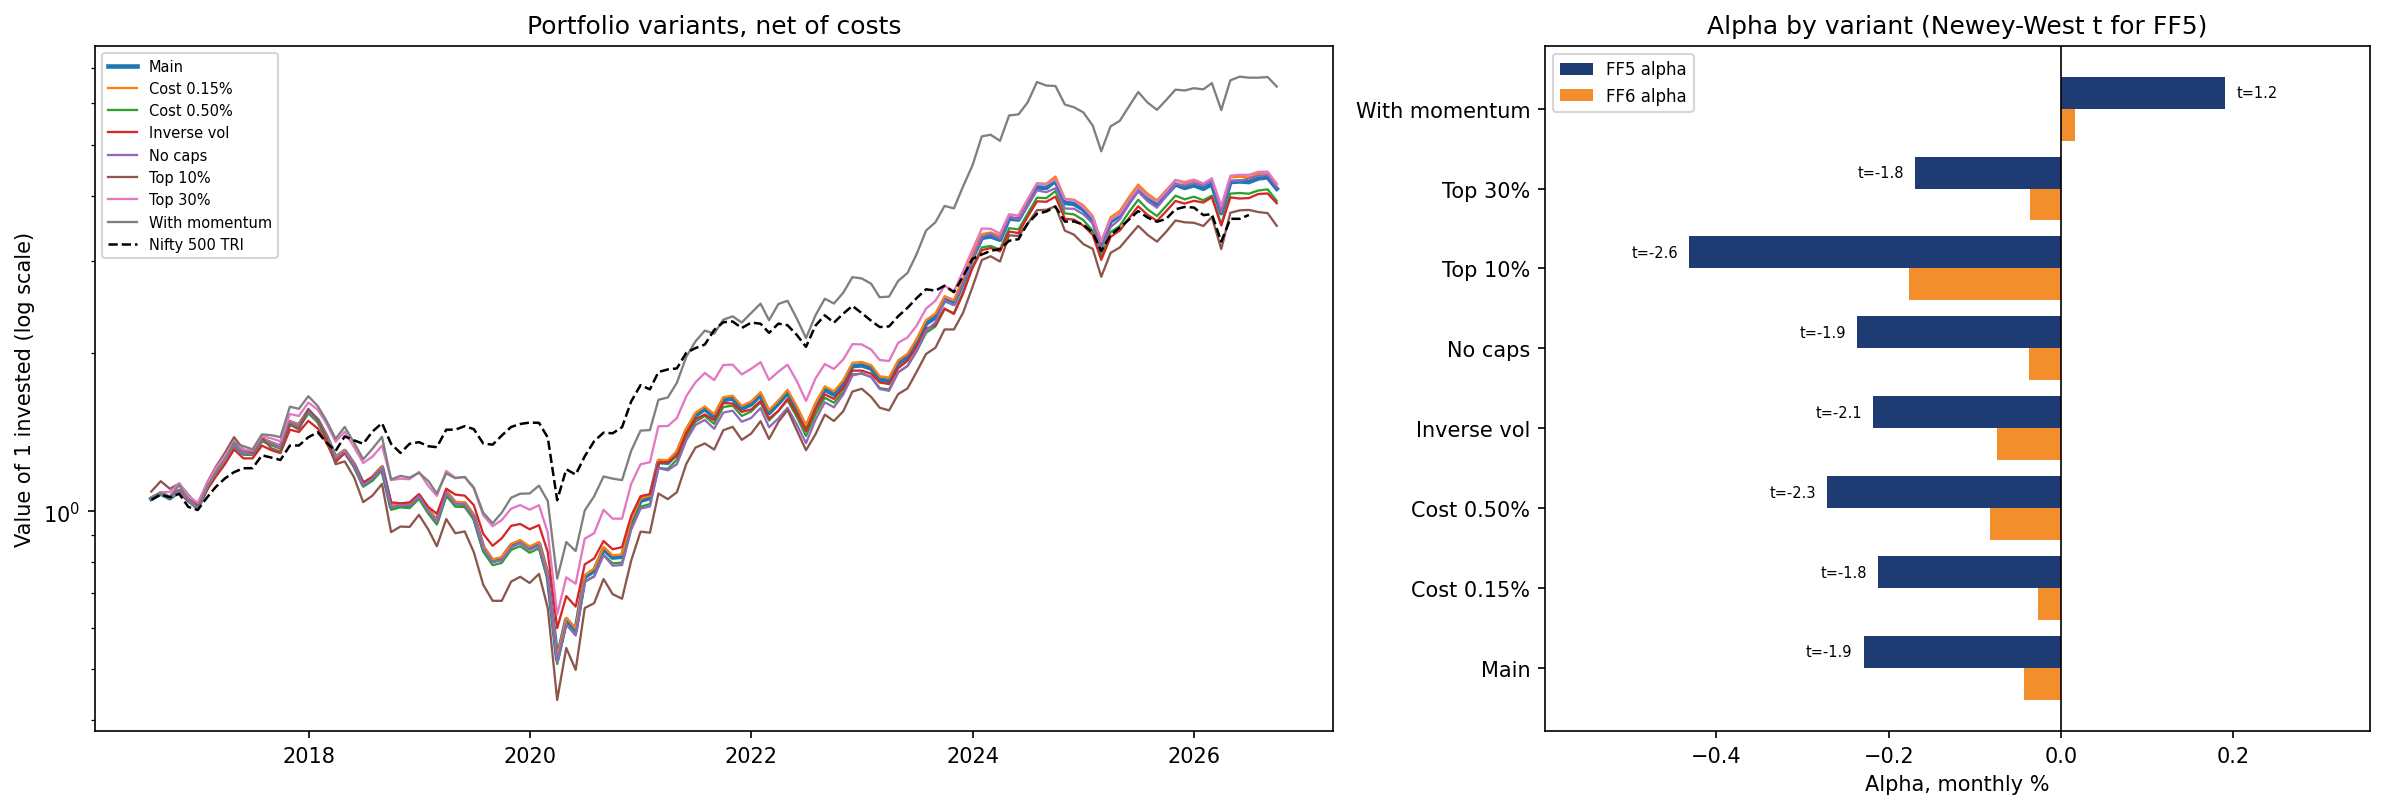

In [51]:
# 8.5 Plots - growth of 1 for each variant (net of costs), and FF5 / FF6 alpha by variant

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), dpi=150, gridspec_kw={"width_ratios": [3, 2]})
palette = sns.color_palette("tab10", len(VARIANTS))
for (name, res), color in zip(variant_returns.items(), palette):
    axes[0].plot((1 + res["net_ret"]).cumprod(), color=color,
                 linewidth=2.2 if name == "Main" else 1.1, label=name)
bench = benchmarks["Nifty 500 TRI"].dropna()
axes[0].plot((1 + bench).cumprod(), "--", color="black", linewidth=1.2, label="Nifty 500 TRI")
axes[0].set_yscale("log")
axes[0].set_ylabel("Value of 1 invested (log scale)")
axes[0].set_title("Portfolio variants, net of costs")
axes[0].legend(fontsize=7, loc="upper left")

y = np.arange(len(port_variants))
axes[1].barh(y + 0.2, port_variants["ff5_alpha_monthly_%"], height=0.4, color="#1f3b73", label="FF5 alpha")
axes[1].barh(y - 0.2, port_variants["ff6_alpha_monthly_%"], height=0.4, color="#f28e2b", label="FF6 alpha")
# t-values just outside the end of each FF5 bar: right of positive bars, left of negative ones
pad = 0.03 * port_variants[["ff5_alpha_monthly_%", "ff6_alpha_monthly_%"]].abs().max().max()
for i, (a, t) in enumerate(zip(port_variants["ff5_alpha_monthly_%"], port_variants["ff5_alpha_t_nw"])):
    axes[1].text(a + pad if a >= 0 else a - pad, i + 0.2, f"t={t:.1f}",
                 ha="left" if a >= 0 else "right", va="center", fontsize=7)
lo, hi = axes[1].get_xlim()
axes[1].set_xlim(lo - 0.2 * (hi - lo), hi + 0.2 * (hi - lo))      # room for the labels
axes[1].set_yticks(y)
axes[1].set_yticklabels(port_variants["variant"])
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Alpha, monthly %")
axes[1].set_title("Alpha by variant (Newey-West t for FF5)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "8_5_portfolio_variants.png", bbox_inches="tight", dpi=300)
plt.show()

In [52]:
# 8.6 Save

port_variants.to_csv(OUTPUT_DIR / "phase_4_portfolio_variants.csv", index=False)
port_periods.to_csv(OUTPUT_DIR / "phase_4_portfolio_periods.csv", index=False)
portfolio_ff6.to_csv(OUTPUT_DIR / "phase_4_portfolio_ff6.csv")
pd.concat(variant_returns, names=["variant"]).reset_index().to_csv(OUTPUT_DIR / "phase_4_portfolio_variant_returns.csv", index=False)
print("Saved: portfolio variants, periods, FF6 loadings, variant returns")
mom_checks.to_csv(OUTPUT_DIR / "phase_4_momentum_variant_checks.csv", index=False)

Saved: portfolio variants, periods, FF6 loadings, variant returns


## Inferences: Portfolio robustness

*The three Phase 3 portfolios are rebuilt exactly (largest difference 1e-16). All figures are net of costs, Jul-2016 to Sep-2026 (123 months). Alphas are monthly %, with Newey-West t.*

**1. Variants of the main portfolio (one change each)**

| Variant | CAGR | Sharpe | Max DD | Turnover a year | Active vs EW universe (t) | FF5 alpha (t) | FF6 alpha (t) | FF5-alpha verdict |
|---|---|---|---|---|---|---|---|---|
| **Main** (EW, top 20%, caps, 0.25%) | 14.8% | 0.45 | −66% | 106% | +0.09 (0.41) | −0.23 (−1.92) | −0.04 (−0.33) | – |
| Cost 0.15% | 15.1% | 0.46 | −66% | 106% | +0.11 (0.48) | −0.21 (−1.79) | −0.03 (−0.21) | Pass |
| Cost 0.50% | 14.2% | 0.43 | −67% | 106% | +0.05 (0.21) | −0.27 (−2.26) | −0.08 (−0.64) | Fragile |
| Inverse vol | 14.1% | 0.45 | −60% | 121% | −0.01 (−0.06) | −0.22 (−2.06) | −0.07 (−0.73) | Fragile |
| No caps | 14.9% | 0.45 | −67% | 102% | +0.11 (0.42) | −0.24 (−1.86) | −0.04 (−0.28) | Pass |
| Top 10% | 13.0% | 0.37 | −72% | 124% | +0.04 (0.15) | −0.43 (−2.60) | −0.18 (−0.90) | Fragile |
| Top 30% | 15.0% | 0.47 | −61% | 102% | +0.08 (0.46) | −0.17 (−1.75) | −0.04 (−0.32) | Pass |
| **With momentum** | **20.0%** | **0.64** | −55% | 247% | **+0.44 (2.11)** | +0.19 (1.25) | +0.02 (0.11) | Pass |

- **The negative FF5 alpha is robust:** it is negative in every FF5-score variant (−0.17% to −0.43% a month). The three Fragile verdicts are cases where it becomes *more* significantly negative (|t| > 2), not sign flips. No variant beats the equal-weighted universe significantly.
- **Costs and caps are not the issue.** Costs from 0.15% to 0.50% move net CAGR only between 15.1% and 14.2% (turnover is a moderate 106% a year), and removing the caps changes almost nothing.
- **The highest-scoring stocks are the worst.** Holding only the top 10% lowers the CAGR to 13.0%, deepens the drawdown to −72% and doubles the negative alpha (−0.43% a month, t = −2.6); the top 30% does slightly better than the main portfolio. The cheapest, most conservative stocks are partly value traps.

**2. Missing momentum explains the negative alpha.**

| FF6 loadings | UMD (t) | FF6 alpha, monthly % (t) | R² |
|---|---|---|---|
| FF5 score, EW | **−0.17 (−4.20)** | −0.04 (−0.33) | 0.97 |
| FF5 score, inverse vol | **−0.13 (−4.92)** | −0.07 (−0.73) | 0.97 |
| FF5 + momentum, EW | **+0.16 (3.98)** | +0.02 (0.11) | 0.96 |

- **The FF5-score portfolio is anti-momentum.** Cheap, slow-growing stocks are usually recent losers. With UMD earning about 0.93% a month (Step 7), that negative loading costs about 0.16% a month. Once UMD is included, the alpha shrinks from −0.23% to −0.04% (t = −0.33). The portfolio has no stock-picking failure; it carries an unintended short-momentum bet.
- **The momentum variant's gains are momentum's premium, not skill.** Its UMD loading is +0.16 (t = 4.0) and its FF6 alpha is zero (+0.02%, t = 0.11). It beats the equal-weighted universe (+5.2% a year, t = 2.1) because it harvests a factor the FF5 score works against.
- **Costs matter more for the momentum variant** (247% turnover): its cost drag is 1.5% a year at 0.25% one-way and about 3% a year at 0.50%. Section 4 tests this.

**3. By period (main portfolio)**

| Period | Months | CAGR | Sharpe | Max DD | Active vs Nifty 500, monthly % (t) | FF5 alpha (t) | FF6 alpha (t) |
|---|---|---|---|---|---|---|---|
| Full sample | 123 | 14.8% | 0.45 | −66% | +0.29 (0.67) | −0.23 (−1.92) | −0.04 (−0.33) |
| First half (2016–21) | 60 | 8.8% | 0.25 | −66% | −0.25 (−0.35) | **−0.38 (−2.46)** | −0.15 (−0.87) |
| Second half (2021–26) | 63 | **20.9%** | 0.77 | −25% | **+0.83 (2.15)** | −0.04 (−0.25) | +0.02 (0.13) |
| Excl. Covid | 119 | 15.4% | 0.51 | −51% | +0.18 (0.42) | −0.28 (−2.13) | −0.13 (−1.06) |

**4. Momentum variant: higher costs and each period (8.3b)**

| Check | CAGR | Sharpe | Max DD | Active vs EW universe, monthly % (t) | Active vs Nifty 500, monthly % (t) | FF5 alpha (t) | FF6 alpha (t) |
|---|---|---|---|---|---|---|---|
| Full sample, 0.25% (Phase 3) | 20.0% | 0.64 | −55% | +0.44 (2.11) | +0.64 (1.63) | +0.19 (1.25) | +0.02 (0.11) |
| Full sample, **0.50% costs** | 18.5% | 0.59 | −57% | +0.33 (1.60) | +0.54 (1.36) | +0.09 (0.58) | −0.08 (−0.58) |
| First half (2016–21) | 16.1% | 0.48 | −55% | +0.20 (0.80) | +0.23 (0.36) | +0.05 (0.20) | −0.10 (−0.44) |
| Second half (2021–26) | 23.8% | 0.87 | −26% | **+0.66 (2.14)** | **+1.06 (2.36)** | +0.16 (0.91) | −0.01 (−0.11) |
| Excl. Covid | 21.2% | 0.74 | −43% | **+0.43 (2.01)** | +0.60 (1.48) | +0.16 (1.08) | −0.04 (−0.29) |

- **At 0.50% costs it still leads, but no longer significantly:** 18.5% a year and about +4.0% a year over the equal-weighted universe (t = 1.6, Fragile). Its edge survives realistic costs only for low-cost execution, at or below 0.25% one-way.
- **It beats the equal-weighted universe in every period**, by +0.20% to +0.66% a month, but significantly only in 2021–26 and without the Covid months. In 2016–21 the lead is small (+2.4% a year, t = 0.8, Fragile).
- **Momentum protected the portfolio in the value crash:** in 2016–21 the momentum variant returned 16.1% a year against 8.8% for the pure FF5-score portfolio. The momentum score avoided much of the falling cheap stocks that dragged the main portfolio down.
- **Still factor harvesting, not skill:** the FF6 alpha is −0.10% to +0.02% a month in every check, never significant. All of its outperformance is explained by its UMD loading.

- **Performance depends on the regime, like HML.** The portfolio lost to the index in 2016–21 (8.8% a year, a −66% drawdown) and beat it significantly in 2021–26 (20.9% a year, +0.83% a month, t = 2.15), during the value/PSU rally.
- **The 2021–26 outperformance is its factor tilts, not selection:** the FF5 alpha in the second half is zero (−0.04%). The negative alpha comes from the first half (−0.38%, t = −2.46), when momentum was strong and the portfolio was short it.
- Without the four Covid months, the drawdown falls from −66% to −51%, but the alpha stays negative.

**Conclusion:** the FF5-score portfolio is a robust but unrewarded design: a high-beta mid-cap value tilt with a hidden short-momentum bet, whose returns depend on the value regime. Adding momentum removes that bet and is the only version that beats the equal-weighted universe, but it does so by earning the momentum premium, at high turnover.


## Step 9: Verdict

1. **Verdict counts:** every Pass / Fragile / Fail from Steps 2–8 in one table, plus the list of everything that is not a Pass.
2. **Phase 3 conclusions tracker:** each main Phase 3 conclusion, checked in every alternative construction and sample period:
   - **C1:** no factor premium is significant (Newey-West |t| > 2)
   - **C2:** HML is redundant (spanning intercept not significant)
   - **C3:** FF5 is rejected at 5% only on the B/M sort
   - **C4:** FF5 does not improve on FF3 (A|a| on all test portfolios)
   - **C5:** FF5's main failure is a positive Mid-row intercept

In [53]:
# 9.1 All verdicts in one table

def verdict_rows(df, step, test, item_cols, verdict_col="verdict"):
    out = pd.DataFrame({
        "step": step, "test": test,
        "item": df[item_cols].astype(str).agg(" | ".join, axis=1),
        "verdict": df[verdict_col],
    })
    return out

val = validation.reset_index()
pv = port_variants[port_variants["variant"] != "Main"]          # Step 8
pp = port_periods[port_periods["period"] != "Full sample"]
mc = mom_checks.iloc[1:]                                        # Step 8.3b
all_verdicts = pd.concat([
    verdict_rows(val, 2, "IIMA correlation", ["factor"], "corr_verdict"),
    verdict_rows(val[val["factor"] != "Rf"], 2, "IIMA premium", ["factor"], "premium_verdict"),
    verdict_rows(alt_premia[alt_premia["version"] != "Baseline"], 3, "Premium, alternative construction", ["version", "factor"]),
    verdict_rows(alt_models[alt_models["version"] != "Baseline"], 3, "GRS, alternative construction", ["version", "model", "sort_type"]),
    verdict_rows(period_premia[period_premia["period"] != "Full sample"], 4, "Premium, sub-period", ["period", "factor"]),
    verdict_rows(period_models[period_models["period"] != "Full sample"], 4, "GRS, sub-period", ["period", "model", "sort_type"]),
    verdict_rows(bootstrap_table, 6, "GRS, bootstrap vs F-test", ["model", "sort_type"]),
    verdict_rows(pv, 8, "Portfolio FF5 alpha, variant", ["variant"], "verdict_ff5_alpha"),
    verdict_rows(pv, 8, "Portfolio active return vs Nifty 500, variant", ["variant"], "verdict_active"),
    verdict_rows(mc, 8, "Momentum variant FF5 alpha", ["check", "period"], "verdict_ff5_alpha"),
    verdict_rows(mc, 8, "Momentum variant active return vs EW universe", ["check", "period"], "verdict_active_ew"),
    verdict_rows(pp, 8, "Portfolio FF5 alpha, sub-period", ["period"], "verdict_ff5_alpha"),
    verdict_rows(pp, 8, "Portfolio active return vs Nifty 500, sub-period", ["period"], "verdict_active"),
    pd.DataFrame({"step": 7, "test": "UMD vs IIMA WML", "item": ["correlation", "premium"],
                  "verdict": [UMD_CORR_VERDICT, UMD_PREMIUM_VERDICT]}),
], ignore_index=True)

verdict_counts = (all_verdicts.pivot_table(index=["step", "test"], columns="verdict", values="item",
                                           aggfunc="count", fill_value=0)
                  .reindex(columns=["Pass", "Fragile", "Fail"], fill_value=0))
display(verdict_counts)
print("Everything that is not a Pass:")
display(all_verdicts[all_verdicts["verdict"] != "Pass"])

verdict                                                Pass  Fragile  Fail
step test                                                                 
2    IIMA correlation                                     4        0     0
     IIMA premium                                         3        0     0
3    GRS, alternative construction                       30        2     0
     Premium, alternative construction                   19        1     0
4    GRS, sub-period                                     33       15     0
     Premium, sub-period                                 14        1     0
6    GRS, bootstrap vs F-test                            18        2     0
7    UMD vs IIMA WML                                      2        0     0
8    Momentum variant FF5 alpha                           4        0     0
     Momentum variant active return vs EW universe        2        2     0
     Portfolio FF5 alpha, sub-period                      1        2     0
     Portfolio FF5 alpha, variant                         4        3     0
     Portfolio active return vs Nifty 500, sub-period     2        1     0
     Portfolio active return vs Nifty 500, variant        7        0     0

Everything that is not a Pass:


,step,test,item,verdict
10,3,"Premium, alternative construction",2x2 sorts | RMW,Fragile
43,3,"GRS, alternative construction",Big = top 100 | FF3 | BM,Fragile
50,3,"GRS, alternative construction",Big = top 100 | FF5 | ALL,Fragile
66,4,"Premium, sub-period",Second half | HML,Fragile
74,4,"GRS, sub-period",First half | CAPM | BM,Fragile
78,4,"GRS, sub-period",First half | FF3 | BM,Fragile
82,4,"GRS, sub-period",First half | FF4_noHML | BM,Fragile
83,4,"GRS, sub-period",First half | FF4_noHML | OP,Fragile
86,4,"GRS, sub-period",First half | FF5 | BM,Fragile
87,4,"GRS, sub-period",First half | FF5 | OP,Fragile


In [54]:
# 9.2 Phase 3 conclusions tracker: each conclusion in every version (Step 3) and period (Step 4)

def conclusions(premia, spans, models, mid):
    ff5 = models[models["model"] == "FF5"].set_index("sort_type")
    ff3 = models[models["model"] == "FF3"].set_index("sort_type")
    significant = premia.loc[premia["t_stat_nw"].abs() > T_CRIT, "factor"].tolist()
    rejected = [s for s in ["BM", "OP", "INV", "ALL"] if ff5.loc[s, "p_value"] < ALPHA]
    return {
        "C1 significant premia": ", ".join(significant) or "none",
        "C2 HML spanning t (NW)": round(spans.set_index("factor").loc["HML", "t_nw"], 2),
        "C3 FF5 rejected sets (5%)": ", ".join(rejected) or "none",
        "C4 A|a| FF3, %": round(ff3.loc["ALL", "avg_abs_a"], 3),
        "C4 A|a| FF5, %": round(ff5.loc["ALL", "avg_abs_a"], 3),
        "C5 FF5 Mid-row avg a, %": round(mid["FF5_mid_row_avg_a_%"].iloc[0], 3),
        "C5 Mid-row significant": int(mid["FF5_mid_row_significant"].iloc[0]),
    }

rows = {}
for name in VERSIONS:
    rows[name] = conclusions(alt_premia[alt_premia["version"] == name],
                             alt_spanning[alt_spanning["version"] == name],
                             alt_models[alt_models["version"] == name],
                             alt_mid[alt_mid["version"] == name])
for name in PERIODS:
    if name == "Full sample":                        # same as "Baseline" above
        continue
    rows[name] = conclusions(period_premia[period_premia["period"] == name],
                             period_spanning[period_spanning["period"] == name],
                             period_models[period_models["period"] == name],
                             period_mid[period_mid["period"] == name])

tracker = pd.DataFrame(rows).T
tracker.index.name = "scenario"
display(tracker)

,C1 significant premia,C2 HML spanning t (NW),C3 FF5 rejected sets (5%),"C4 A|a| FF3, %","C4 A|a| FF5, %","C5 FF5 Mid-row avg a, %",C5 Mid-row significant
scenario,,,,,,,
Baseline,none,1.06,BM,0.13,0.141,0.174,4
2x2 sorts,RMW,0.78,BM,0.132,0.135,0.144,2
Excl. financials,none,0.99,BM,0.134,0.153,0.205,4
Big = top 100,none,0.07,"BM, ALL",0.132,0.135,0.074,2
Equal-weighted,none,0.98,BM,0.147,0.155,0.167,3
First half,none,-0.66,OP,0.213,0.233,0.208,3
Second half,HML,2.08,INV,0.227,0.227,0.22,2
Excl. Covid,none,1.24,none,0.123,0.123,0.15,2


## Inferences: Verdict

**1. Verdict counts: 137 Pass, 27 Fragile, 0 Fail (164 checks).**

| Check | Pass | Fragile | Fail |
|---|---|---|---|
| IIMA correlation and premium (Step 2) | 7 | 0 | 0 |
| Premium, alternative constructions (Step 3) | 19 | 1 | 0 |
| GRS, alternative constructions (Step 3) | 30 | 2 | 0 |
| Premium, sub-periods (Step 4) | 14 | 1 | 0 |
| GRS, sub-periods (Step 4) | 33 | 15 | 0 |
| GRS, bootstrap vs F-test (Step 6) | 18 | 2 | 0 |
| UMD vs IIMA WML (Step 7) | 2 | 0 | 0 |
| Portfolio FF5 alpha, variants (Step 8) | 4 | 3 | 0 |
| Portfolio active return vs Nifty 500, variants (Step 8) | 7 | 0 | 0 |
| Portfolio FF5 alpha, sub-periods (Step 8) | 1 | 2 | 0 |
| Portfolio active return vs Nifty 500, sub-periods (Step 8) | 2 | 1 | 0 |

- No result reversed sign while significant.
- 12 of the 15 Fragile sub-period GRS verdicts are on the B/M sort.
- All 5 Fragile portfolio-alpha verdicts are the negative FF5 alpha becoming *more* significant; the single Fragile active-return verdict is the second half turning significantly positive.

**2. Phase 3 conclusions**

| # | Phase 3 conclusion | Evidence | Verdict |
|---|---|---|---|
| C1 | No factor premium is significant | Holds in 6 of 8 scenarios; exceptions: RMW with 2×2 sorts (t = −2.15), HML in 2021–26 (t = 3.02) | **Pass**, with a regime caveat for HML |
| C2 | HML is redundant (spanned by RMW and CMA) | Holds in 7 of 8; fails in the second half (t = 2.08) | **Fragile:** true for the full sample only |
| C3 | FF5 is rejected only on the B/M sort | Holds in 4 of 5 constructions; not rejected without the Covid months nor by bootstrap (p = 0.052) | **Fragile:** FF5 sits at the 5% line on B/M |
| C4 | FF5 does not improve on FF3 | Holds in all 8 scenarios | **Pass** |
| C5 | FF5's main failure is a positive mid-cap intercept | Positive in all 8 (+0.07% to +0.22% a month); shrinks to +0.07% with Big = top 100 | **Pass** on sign; size depends on the size breakpoint |
| C6 | The FF5-score portfolio does not beat the equal-weighted universe and has a negative FF5 alpha | Negative FF5 alpha in all 7 variants; no variant beats the EW universe significantly; FF6 alpha ≈ 0 everywhere (a negative UMD loading, t = −4.2) | **Pass:** robust, and explained by missing momentum |
| C7 | Adding momentum gives the only portfolio that beats the equal-weighted universe | +5.2% a year (t = 2.1), Sharpe 0.64; FF6 alpha +0.02% (t = 0.11); 247% turnover | **Pass, as factor exposure:** it earns the momentum premium, not alpha; cost-sensitive |


In [55]:
# 9.3 Save, and one Excel workbook of all Phase 4 tables

all_verdicts.to_csv(OUTPUT_DIR / "phase_4_all_verdicts.csv", index=False)
verdict_counts.to_csv(OUTPUT_DIR / "phase_4_verdict_counts.csv")
tracker.to_csv(OUTPUT_DIR / "phase_4_conclusions_tracker.csv")

# One sheet per Phase 4 CSV (sheet name = file name without "phase_4_", max 31 characters)
with pd.ExcelWriter(OUTPUT_DIR / "phase_4_results.xlsx", engine="openpyxl") as writer:
    for csv_path in sorted(OUTPUT_DIR.glob("phase_4_*.csv")):
        table = pd.read_csv(csv_path).rename(columns={"Unnamed: 0": "name"})
        table.to_excel(writer, sheet_name=csv_path.stem.replace("phase_4_", "")[:31], index=False)
        print("Sheet added:", csv_path.stem.replace("phase_4_", "")[:31])
print("Saved: phase_4_results.xlsx")

Sheet added: all_verdicts
Sheet added: alt_factors
Sheet added: alt_mid_row
Sheet added: alt_models
Sheet added: alt_premia
Sheet added: alt_spanning
Sheet added: baseline_factors
Sheet added: baseline_models
Sheet added: bootstrap_grs
Sheet added: conclusions_tracker
Sheet added: external_validation
Sheet added: factors_with_umd
Sheet added: iima_factors
Sheet added: industry_ff5
Sheet added: industry_models
Sheet added: industry_returns
Sheet added: market_index_check
Sheet added: momentum_models
Sheet added: momentum_variant_checks
Sheet added: nse_tri_monthly
Sheet added: period_mid_row
Sheet added: period_models
Sheet added: period_premia
Sheet added: period_spanning
Sheet added: portfolio_ff6
Sheet added: portfolio_periods
Sheet added: portfolio_variant_returns
Sheet added: portfolio_variants
Sheet added: residual_normality
Sheet added: smb_index_check
Sheet added: umd_check
Sheet added: umd_spanning
Sheet added: v1_vs_v2_baseline
Sheet added: v1_vs_v2_validation
Sheet added: ver

## Phase 4 summary

**Data and factors are validated.**
- After the Phase 1 rebuild, the market return matches the Nifty 500 TRI (CAGR 14.06% vs 13.90%, tracking error 2.1%), and SMB matches the survivorship-free index spreads.
- MKT, SMB and HML correlate 0.79–0.98 with IIMA's factors and lead to the same conclusions.
- The factors keep their sign and significance verdict under 2×2 sorts, without financials, with a top-100 size breakpoint and with equal weights (19 of 20 premium verdicts Pass).
- **Overall: 164 checks, 137 Pass, 27 Fragile, 0 Fail.**

**What holds**
- No FF5 premium is reliably significant over Jul-2016 to Sep-2026 (≈ 10 years); FF5 never prices better than FF3; FF5 is not rejected on all 27 test portfolios or on 11 industry portfolios.
- Mid-caps earn a positive FF5 intercept in every scenario.
- **Momentum** (UMD, 11% a year, t = 3.0) is the one strong premium, FF5 does not explain it, and it is the only significant characteristic in stock-level Fama-MacBeth regressions (Phase 3).
- **The FF5-score portfolio** (Phase 3) does not beat the equal-weighted universe in any variant. Its negative FF5 alpha (−2.7% a year) comes from a hidden short-momentum exposure (UMD loading −0.17, t = −4.2); with momentum controlled, its alpha is zero.

**What is fragile**
- **HML is regime-dependent:** zero in 2016–21, 12.9% a year in 2021–26, and redundant only in the full sample.
- **The B/M rejection of FF5 is borderline:** p = 0.037 (F-test), 0.052 (bootstrap), not rejected without the Covid months.
- **About 60% of the mid-cap intercept comes from the median size split.**
- **Portfolio results depend on the regime:** the FF5-score portfolio lost to the Nifty 500 in 2016–21 (−66% drawdown) and beat it in 2021–26 (20.9% a year), entirely through its value tilt.

**What Phase 5 should use**
1. **FF5 as the main attribution model,** reported together with **FF6 (FF5 + UMD)**. Without UMD, momentum-heavy funds look skilled and value funds look unskilled.
2. **Alpha screening with care:** Newey-West t-stats, FF5 and FF6 alphas side by side, a flag for mid-cap tilts (partly a model effect), and HML exposure read as regime exposure.
3. **Portfolio for the dashboard:** the **FF5 + momentum** portfolio as the main showcase (best net return and Sharpe, beats the equal-weighted universe), presented honestly as factor harvesting (FF6 alpha ≈ 0) with high turnover. The pure FF5-score portfolio is shown as the reference design.
4. **Costs and risk shown in full:** turnover, cost drag and drawdowns, not just returns.

**Limitations:** 123 months (about 60 per half), so tests have low power and a few significant results are expected by chance across about 160 checks; the NSE TRI series end in Jun-2026; RMW and CMA have no external benchmark; industry labels are current, not point-in-time; portfolio returns are before tax and assume no loss on non-merger delistings.
